# install necessary libary

In [1]:
!pip install pandas numpy scikit-learn xgboost matplotlib seaborn
!pip install xgboost lightgbm catboost joblib flask 

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
import warnings

warnings.filterwarnings("ignore")

from sklearn.preprocessing import OneHotEncoder, MultiLabelBinarizer, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    RandomizedSearchCV
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)



In [3]:
#read csv file
train_data=pd.read_csv("train.csv")
test_data=pd.read_csv("test.csv")

# DATA analysis

In [4]:
train_data.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,_,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good
2,0x1604,CUS_0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.2098628537912,Good
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.4580743910713,Low_spent_Small_value_payments,223.45130972736786,Good
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,Good,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153086217326,High_spent_Medium_value_payments,341.48923103222177,Good


In [5]:
test_data.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance
0,0x160a,CUS_0xd40,September,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,2022.0,Good,809.98,35.030402,22 Years and 9 Months,No,49.574949,236.64268203272135,Low_spent_Small_value_payments,186.26670208571772
1,0x160b,CUS_0xd40,October,Aaron Maashoh,24,821-00-0265,Scientist,19114.12,1824.843333,3,...,4.0,Good,809.98,33.053114,22 Years and 10 Months,No,49.574949,21.465380264657146,High_spent_Medium_value_payments,361.44400385378196
2,0x160c,CUS_0xd40,November,Aaron Maashoh,24,821-00-0265,Scientist,19114.12,1824.843333,3,...,4.0,Good,809.98,33.811894,NaN,No,49.574949,148.23393788500925,Low_spent_Medium_value_payments,264.67544623342997
3,0x160d,CUS_0xd40,December,Aaron Maashoh,24_,821-00-0265,Scientist,19114.12,NaN,3,...,4.0,Good,809.98,32.430559,23 Years and 0 Months,No,49.574949,39.08251089460281,High_spent_Medium_value_payments,343.82687322383634
4,0x1616,CUS_0x21b1,September,Rick Rothackerj,28,004-07-5839,_______,34847.84,3037.986667,2,...,5.0,Good,605.03,25.926822,27 Years and 3 Months,No,18.816215,39.684018417945296,High_spent_Large_value_payments,485.2984336755923


In [6]:
print(train_data.info())


<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  str    
 1   Customer_ID               100000 non-null  str    
 2   Month                     100000 non-null  str    
 3   Name                      90015 non-null   str    
 4   Age                       100000 non-null  str    
 5   SSN                       100000 non-null  str    
 6   Occupation                100000 non-null  str    
 7   Annual_Income             100000 non-null  str    
 8   Monthly_Inhand_Salary     84998 non-null   float64
 9   Num_Bank_Accounts         100000 non-null  int64  
 10  Num_Credit_Card           100000 non-null  int64  
 11  Interest_Rate             100000 non-null  int64  
 12  Num_of_Loan               100000 non-null  str    
 13  Type_of_Loan              88592 non-null   str    
 14  

In [7]:
print(test_data.info())

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 27 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        50000 non-null  str    
 1   Customer_ID               50000 non-null  str    
 2   Month                     50000 non-null  str    
 3   Name                      44985 non-null  str    
 4   Age                       50000 non-null  str    
 5   SSN                       50000 non-null  str    
 6   Occupation                50000 non-null  str    
 7   Annual_Income             50000 non-null  str    
 8   Monthly_Inhand_Salary     42502 non-null  float64
 9   Num_Bank_Accounts         50000 non-null  int64  
 10  Num_Credit_Card           50000 non-null  int64  
 11  Interest_Rate             50000 non-null  int64  
 12  Num_of_Loan               50000 non-null  str    
 13  Type_of_Loan              44296 non-null  str    
 14  Delay_from_due_da

In [8]:
train_data.describe()

,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Delay_from_due_date,Num_Credit_Inquiries,Credit_Utilization_Ratio,Total_EMI_per_month
count,84998.000000,100000.000000,100000.00000,100000.000000,100000.000000,98035.000000,100000.000000,100000.000000
mean,4194.170850,17.091280,22.47443,72.466040,21.068780,27.754251,32.285173,1403.118217
std,3183.686167,117.404834,129.05741,466.422621,14.860104,193.177339,5.116875,8306.041270
min,303.645417,-1.000000,0.00000,1.000000,-5.000000,0.000000,20.000000,0.000000
25%,1625.568229,3.000000,4.00000,8.000000,10.000000,3.000000,28.052567,30.306660
50%,3093.745000,6.000000,5.00000,13.000000,18.000000,6.000000,32.305784,69.249473
75%,5957.448333,7.000000,7.00000,20.000000,28.000000,9.000000,36.496663,161.224249
max,15204.633333,1798.000000,1499.00000,5797.000000,67.000000,2597.000000,50.000000,82331.000000


In [9]:
test_data.describe()

,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Delay_from_due_date,Num_Credit_Inquiries,Credit_Utilization_Ratio,Total_EMI_per_month
count,42502.000000,50000.000000,50000.000000,50000.000000,50000.000000,48965.000000,50000.000000,50000.000000
mean,4182.004291,16.838260,22.921480,68.772640,21.052640,30.080200,32.279581,1491.304305
std,3174.109304,116.396848,129.314804,451.602363,14.860397,196.984121,5.106238,8595.647887
min,303.645417,-1.000000,0.000000,1.000000,-5.000000,0.000000,20.509652,0.000000
25%,1625.188333,3.000000,4.000000,8.000000,10.000000,4.000000,28.061040,32.222388
50%,3086.305000,6.000000,5.000000,13.000000,18.000000,7.000000,32.280390,74.733349
75%,5934.189094,7.000000,7.000000,20.000000,28.000000,10.000000,36.468591,176.157491
max,15204.633333,1798.000000,1499.000000,5799.000000,67.000000,2593.000000,48.540663,82398.000000


In [10]:
train_data.isna().sum()

ID                              0
Customer_ID                     0
Month                           0
Name                         9985
Age                             0
SSN                             0
Occupation                      0
Annual_Income                   0
Monthly_Inhand_Salary       15002
Num_Bank_Accounts               0
Num_Credit_Card                 0
Interest_Rate                   0
Num_of_Loan                     0
Type_of_Loan                11408
Delay_from_due_date             0
Num_of_Delayed_Payment       7002
Changed_Credit_Limit            0
Num_Credit_Inquiries         1965
Credit_Mix                      0
Outstanding_Debt                0
Credit_Utilization_Ratio        0
Credit_History_Age           9030
Payment_of_Min_Amount           0
Total_EMI_per_month             0
Amount_invested_monthly      4479
Payment_Behaviour               0
Monthly_Balance              1200
Credit_Score                    0
dtype: int64

In [11]:
# Get the list of column names
print(train_data.columns.tolist())
print(test_data.columns.tolist())

['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance', 'Credit_Score']
['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation', 'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_of_Min_Amount', 'Total_EMI_per_month', 'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance'

# data cleaning

In [12]:
#check duplicate data:no duplicate data
print(train_data.duplicated().value_counts())
print(test_data.duplicated().value_counts())

False    100000
Name: count, dtype: int64
False    50000
Name: count, dtype: int64


In [13]:
# Show dataset shapes
print("Train shape:", train_data.shape)
print("Test shape:", test_data.shape)

Train shape: (100000, 28)
Test shape: (50000, 27)


In [14]:
# Show first 5 rows
print(train_data.head())

# Show column names
print(train_data.columns.tolist())

# Show data information
train_data.info()

       ID Customer_ID     Month           Name   Age          SSN Occupation  \
0  0x1602   CUS_0xd40   January  Aaron Maashoh    23  821-00-0265  Scientist   
1  0x1603   CUS_0xd40  February  Aaron Maashoh    23  821-00-0265  Scientist   
2  0x1604   CUS_0xd40     March  Aaron Maashoh  -500  821-00-0265  Scientist   
3  0x1605   CUS_0xd40     April  Aaron Maashoh    23  821-00-0265  Scientist   
4  0x1606   CUS_0xd40       May  Aaron Maashoh    23  821-00-0265  Scientist   

  Annual_Income  Monthly_Inhand_Salary  Num_Bank_Accounts  ...  Credit_Mix  \
0      19114.12            1824.843333                  3  ...           _   
1      19114.12                    NaN                  3  ...        Good   
2      19114.12                    NaN                  3  ...        Good   
3      19114.12                    NaN                  3  ...        Good   
4      19114.12            1824.843333                  3  ...        Good   

   Outstanding_Debt Credit_Utilization_Ratio     C

In [15]:
# Remove extra spaces from column names
train_data.columns = train_data.columns.str.strip()
test_data.columns = test_data.columns.str.strip()

In [16]:
# Define unnecessary columns
drop_cols = ["ID", "Customer_ID", "Name", "SSN"]

# Remove unnecessary columns from train
train_data.drop(
    columns=[col for col in drop_cols if col in train_data.columns],
    inplace=True
)

# Remove unnecessary columns from test
test_data.drop(
    columns=[col for col in drop_cols if col in test_data.columns],
    inplace=True
)

In [17]:
# Remove extra spaces from train text columns
for col in train_data.select_dtypes(include="object").columns:
    train_data[col] = train_data[col].astype(str).str.strip()

# Remove extra spaces from test text columns
for col in test_data.select_dtypes(include="object").columns:
    test_data[col] = test_data[col].astype(str).str.strip()

In [18]:
# Convert special-character-only values to NaN
for col in train_data.select_dtypes(include="object").columns:
    train_data[col] = train_data[col].replace(
        r"^[^A-Za-z0-9\s]+$",
        np.nan,
        regex=True
    )

# Do the same for test data
for col in test_data.select_dtypes(include="object").columns:
    test_data[col] = test_data[col].replace(
        r"^[^A-Za-z0-9\s]+$",
        np.nan,
        regex=True
    )

In [19]:
# Define common missing values
missing_values = [
    "",
    "NA",
    "N/A",
    "na",
    "n/a",
    "None",
    "none",
    "null",
    "NULL",
    "?",
    "nan"
]

# Replace them with NaN
train_data.replace(missing_values, np.nan, inplace=True)
test_data.replace(missing_values, np.nan, inplace=True)

,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,...,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance
0,September,23,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,2022.0,Good,809.98,35.030402,22 Years and 9 Months,No,49.574949,236.64268203272135,Low_spent_Small_value_payments,186.26670208571772
1,October,24,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,4.0,Good,809.98,33.053114,22 Years and 10 Months,No,49.574949,21.465380264657146,High_spent_Medium_value_payments,361.44400385378196
2,November,24,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,4.0,Good,809.98,33.811894,NaN,No,49.574949,148.23393788500925,Low_spent_Medium_value_payments,264.67544623342997
3,December,24_,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",...,4.0,Good,809.98,32.430559,23 Years and 0 Months,No,49.574949,39.08251089460281,High_spent_Medium_value_payments,343.82687322383634
4,September,28,NaN,34847.84,3037.986667,2,4,6,1,Credit-Builder Loan,...,5.0,Good,605.03,25.926822,27 Years and 3 Months,No,18.816215,39.684018417945296,High_spent_Large_value_payments,485.2984336755923
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,December,4975,Architect,20002.88,1929.906667,10,8,29,5,"Personal Loan, Auto Loan, Mortgage Loan, Stude...",...,12.0,NaN,3571.7,34.780553,NaN,Yes,60.964772,146.48632477751087,Low_spent_Small_value_payments,275.53956951573343
49996,September,25,Mechanic,39628.99,NaN,4,6,7,2_,"Auto Loan, and Student Loan",...,7.0,Good,502.38,27.758522,31 Years and 11 Months,NM,35.104023,181.44299902757518,Low_spent_Small_value_payments,409.39456169535066
49997,October,25,Mechanic,39628.99,3359.415833,4,6,7,2,"Auto Loan, and Student Loan",...,7.0,Good,502.38,36.858542,32 Years and 0 Months,No,35.104023,__10000__,Low_spent_Large_value_payments,349.7263321025098
49998,November,25,Mechanic,39628.99,NaN,4,6,7,2_,"Auto Loan, and Student Loan",...,7.0,Good,502.38,39.139840,32 Years and 1 Months,No,35.104023,97.59857973344877,High_spent_Small_value_payments,463.23898098947717


In [20]:
# Define numerical columns
numeric_cols = [
    "Age",
    "Annual_Income",
    "Monthly_Inhand_Salary",
    "Num_Bank_Accounts",
    "Num_Credit_Card",
    "Interest_Rate",
    "Num_of_Loan",
    "Delay_from_due_date",
    "Num_of_Delayed_Payment",
    "Changed_Credit_Limit",
    "Num_Credit_Inquiries",
    "Outstanding_Debt",
    "Credit_Utilization_Ratio",
    "Total_EMI_per_month",
    "Amount_invested_monthly",
    "Monthly_Balance"
]

In [21]:
# Clean train numerical columns
for col in numeric_cols:

    if col in train_data.columns:
        train_data[col] = pd.to_numeric(
            train_data[col]
            .astype(str)
            .str.replace("_", "", regex=False),
            errors="coerce"
        )

# Clean test numerical columns
for col in numeric_cols:

    if col in test_data.columns:
        test_data[col] = pd.to_numeric(
            test_data[col]
            .astype(str)
            .str.replace("_", "", regex=False),
            errors="coerce"
        )

In [22]:
# Check negative values in train data
for col in numeric_cols:

    if col in train_data.columns:

        count = (train_data[col] < 0).sum()

        if count > 0:
            print(col, ":", count)

Age : 886
Num_Bank_Accounts : 21
Num_of_Loan : 3876
Delay_from_due_date : 591
Num_of_Delayed_Payment : 644
Changed_Credit_Limit : 1586
Monthly_Balance : 9


In [23]:
# Define columns where negative values are impossible
non_negative_cols = [
    "Age",
    "Annual_Income",
    "Monthly_Inhand_Salary",
    "Num_Bank_Accounts",
    "Num_Credit_Card",
    "Interest_Rate",
    "Num_of_Loan",
    "Delay_from_due_date",
    "Num_of_Delayed_Payment",
    "Num_Credit_Inquiries",
    "Outstanding_Debt",
    "Credit_Utilization_Ratio",
    "Total_EMI_per_month",
    "Amount_invested_monthly",
    "Monthly_Balance"
]



In [24]:
# Replace negative values with NaN in train
for col in non_negative_cols:

    if col in train_data.columns:
        train_data.loc[
            train_data[col] < 0,
            col
        ] = np.nan

# Replace negative values with NaN in test
for col in non_negative_cols:

    if col in test_data.columns:
        test_data.loc[
            test_data[col] < 0,
            col
        ] = np.nan

In [25]:
# Replace impossible age values with NaN
train_data.loc[
    (train_data["Age"] <= 0) |
    (train_data["Age"] > 100),
    "Age"
] = np.nan

# Do the same for test
test_data.loc[
    (test_data["Age"] <= 0) |
    (test_data["Age"] > 100),
    "Age"
] = np.nan

In [26]:
# Check minimum and maximum values
for col in numeric_cols:

    if col in train_data.columns:
        print(
            col,
            "Min =", train_data[col].min(),
            "Max =", train_data[col].max()
        )

Age Min = 14.0 Max = 100.0
Annual_Income Min = 7005.93 Max = 24198062.0
Monthly_Inhand_Salary Min = 303.6454166666666 Max = 15204.633333333331
Num_Bank_Accounts Min = 0.0 Max = 1798.0
Num_Credit_Card Min = 0.0 Max = 1499.0
Interest_Rate Min = 1.0 Max = 5797.0
Num_of_Loan Min = 0.0 Max = 1496.0
Delay_from_due_date Min = 0.0 Max = 67.0
Num_of_Delayed_Payment Min = 0.0 Max = 4397.0
Changed_Credit_Limit Min = -6.49 Max = 36.97
Num_Credit_Inquiries Min = 0.0 Max = 2597.0
Outstanding_Debt Min = 0.23 Max = 4998.07
Credit_Utilization_Ratio Min = 20.0 Max = 50.00000000000001
Total_EMI_per_month Min = 0.0 Max = 82331.0
Amount_invested_monthly Min = 0.0 Max = 10000.0
Monthly_Balance Min = 0.0077596647753352 Max = 1602.0405189622518


In [27]:
# Define maximum reasonable limits
max_limits = {
    "Age": 100,
    "Num_Bank_Accounts": 50,
    "Num_Credit_Card": 50,
    "Num_of_Loan": 50,
    "Interest_Rate": 100,
    "Delay_from_due_date": 365,
    "Num_of_Delayed_Payment": 365,
    "Num_Credit_Inquiries": 100,
    "Credit_Utilization_Ratio": 100
}

# Replace extreme values with NaN in train
for col, limit in max_limits.items():

    if col in train_data.columns:
        train_data.loc[
            train_data[col] > limit,
            col
        ] = np.nan

# Replace extreme values with NaN in test
for col, limit in max_limits.items():

    if col in test_data.columns:
        test_data.loc[
            test_data[col] > limit,
            col
        ] = np.nan

In [28]:
# Convert Credit_History_Age to months
def convert_age(x):

    try:
        # Convert value to string
        x = str(x)

        # Get years
        years = int(x.split()[0])

        # Get months
        months = int(x.split()[3])

        # Convert to total months
        return years * 12 + months

    except:
        # Return NaN for invalid values
        return np.nan

In [29]:
# Convert train Credit_History_Age
train_data["Credit_History_Age"] = train_data[
    "Credit_History_Age"
].apply(convert_age)

# Convert test Credit_History_Age
test_data["Credit_History_Age"] = test_data[
    "Credit_History_Age"
].apply(convert_age)

In [30]:
# Replace negative credit history age with NaN
train_data.loc[
    train_data["Credit_History_Age"] < 0,
    "Credit_History_Age"
] = np.nan

# Do the same for test
test_data.loc[
    test_data["Credit_History_Age"] < 0,
    "Credit_History_Age"
] = np.nan

In [31]:
# Add Credit_History_Age to numerical columns
numeric_cols.append("Credit_History_Age")

In [32]:
# Fill numerical missing values
for col in numeric_cols:

    if col in train_data.columns:

        # Calculate median from train data
        median_value = train_data[col].median()

        # Fill train missing values
        train_data[col] = train_data[col].fillna(
            median_value
        )

        # Fill test missing values using train median
        if col in test_data.columns:
            test_data[col] = test_data[col].fillna(
                median_value
            )

In [33]:
# Find categorical columns
categorical_cols = train_data.select_dtypes(
    include="object"
).columns.tolist()

# Remove target column
if "Credit_Score" in categorical_cols:
    categorical_cols.remove("Credit_Score")

# Show categorical columns
print(categorical_cols)

['Month', 'Occupation', 'Type_of_Loan', 'Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour']


In [34]:
# Fill categorical missing values
for col in categorical_cols:

    # Calculate mode from train data
    mode_value = train_data[col].mode()[0]

    # Fill train missing values
    train_data[col] = train_data[col].fillna(
        mode_value
    )

    # Fill test missing values using train mode
    if col in test_data.columns:
        test_data[col] = test_data[col].fillna(
            mode_value
        )

In [35]:
# Remove spaces from Credit_Score
train_data["Credit_Score"] = (
    train_data["Credit_Score"]
    .astype(str)
    .str.strip()
)

# Check target values
print(train_data["Credit_Score"].value_counts())

Credit_Score
Standard    53174
Poor        28998
Good        17828
Name: count, dtype: int64


In [36]:
# Remove rows where target is missing
train_data = train_data.dropna(
    subset=["Credit_Score"]
)

In [37]:
# Check remaining missing values in train
train_missing = train_data.isnull().sum()

print("Train missing values:")
print(train_missing[train_missing > 0])

Train missing values:
Series([], dtype: int64)


In [38]:
# Check remaining missing values in test
test_missing = test_data.isnull().sum()

print("Test missing values:")
print(test_missing[test_missing > 0])

Test missing values:
Series([], dtype: int64)


In [39]:
# Check remaining negative values
for col in numeric_cols:

    if col in train_data.columns:

        count = (train_data[col] < 0).sum()

        if count > 0:
            print(col, ":", count)

Changed_Credit_Limit : 1586


In [40]:
# Check duplicate rows
print("Train duplicates:", train_data.duplicated().sum())
print("Test duplicates:", test_data.duplicated().sum())

Train duplicates: 0
Test duplicates: 0


In [41]:
# Remove duplicate rows
train_data = train_data.drop_duplicates()
test_data = test_data.drop_duplicates()

In [42]:
# Show unique values of categorical columns
for col in categorical_cols:

    print("\n", col)
    print(train_data[col].unique())


 Month
<StringArray>
['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August']
Length: 8, dtype: str

 Occupation
<StringArray>
[    'Scientist',        'Lawyer',       'Teacher',      'Engineer',
  'Entrepreneur',     'Developer', 'Media_Manager',        'Doctor',
    'Journalist',       'Manager',    'Accountant',      'Musician',
      'Mechanic',        'Writer',     'Architect']
Length: 15, dtype: str

 Type_of_Loan
<StringArray>
[                                                     'Auto Loan, Credit-Builder Loan, Personal Loan, and Home Equity Loan',
                                                                                                      'Credit-Builder Loan',
                                                                                  'Auto Loan, Auto Loan, and Not Specified',
                                                                                                            'Not Specified',
                                           

In [43]:
# Find the mode of Payment_Behaviour
mode_value = train_data["Payment_Behaviour"].mode()[0]

# Replace !@9#%8 with the mode in train data
train_data["Payment_Behaviour"] = train_data[
    "Payment_Behaviour"
].replace("!@9#%8", mode_value)

# Replace !@9#%8 with the same train mode in test data
test_data["Payment_Behaviour"] = test_data[
    "Payment_Behaviour"
].replace("!@9#%8", mode_value)

# Check the result
print("Mode:", mode_value)
print(train_data["Payment_Behaviour"].value_counts())

Mode: Low_spent_Small_value_payments
Payment_Behaviour
Low_spent_Small_value_payments      33113
High_spent_Medium_value_payments    17540
Low_spent_Medium_value_payments     13861
High_spent_Large_value_payments     13721
High_spent_Small_value_payments     11340
Low_spent_Large_value_payments      10425
Name: count, dtype: int64


In [44]:
# Check target counts
print(train_data["Credit_Score"].value_counts())

Credit_Score
Standard    53174
Poor        28998
Good        17828
Name: count, dtype: int64


In [45]:
# Check target percentages
print(
    train_data["Credit_Score"]
    .value_counts(normalize=True) * 100
)

Credit_Score
Standard    53.174
Poor        28.998
Good        17.828
Name: proportion, dtype: float64


In [46]:
# Check final train information
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 24 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Month                     100000 non-null  str    
 1   Age                       100000 non-null  float64
 2   Occupation                100000 non-null  str    
 3   Annual_Income             100000 non-null  float64
 4   Monthly_Inhand_Salary     100000 non-null  float64
 5   Num_Bank_Accounts         100000 non-null  float64
 6   Num_Credit_Card           100000 non-null  float64
 7   Interest_Rate             100000 non-null  float64
 8   Num_of_Loan               100000 non-null  float64
 9   Type_of_Loan              100000 non-null  str    
 10  Delay_from_due_date       100000 non-null  float64
 11  Num_of_Delayed_Payment    100000 non-null  float64
 12  Changed_Credit_Limit      100000 non-null  float64
 13  Num_Credit_Inquiries      100000 non-null  float64
 14  

In [47]:
# Check final test information
test_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Month                     50000 non-null  str    
 1   Age                       50000 non-null  float64
 2   Occupation                50000 non-null  str    
 3   Annual_Income             50000 non-null  float64
 4   Monthly_Inhand_Salary     50000 non-null  float64
 5   Num_Bank_Accounts         50000 non-null  float64
 6   Num_Credit_Card           50000 non-null  float64
 7   Interest_Rate             50000 non-null  float64
 8   Num_of_Loan               50000 non-null  float64
 9   Type_of_Loan              50000 non-null  str    
 10  Delay_from_due_date       50000 non-null  float64
 11  Num_of_Delayed_Payment    50000 non-null  float64
 12  Changed_Credit_Limit      50000 non-null  float64
 13  Num_Credit_Inquiries      50000 non-null  float64
 14  Credit_Mix       

In [48]:
# Show final shapes
print("Final train shape:", train_data.shape)
print("Final test shape:", test_data.shape)

Final train shape: (100000, 24)
Final test shape: (50000, 23)


In [49]:
# Save cleaned train data
train_data.to_csv(
    "clean_train_data.csv",
    index=False
)

# Save cleaned test data
test_data.to_csv(
    "clean_test_data.csv",
    index=False
)

# Show success message
print("Data cleaning completed successfully!")

Data cleaning completed successfully!


# visualization

In [50]:
clean_train_data=pd.read_csv("clean_train_data.csv")
clean_test_data=pd.read_csv("clean_test_data.csv")

In [51]:
# Check shape
print("Train:", clean_train_data.shape)
print("Test:", clean_test_data.shape)

Train: (100000, 24)
Test: (50000, 23)


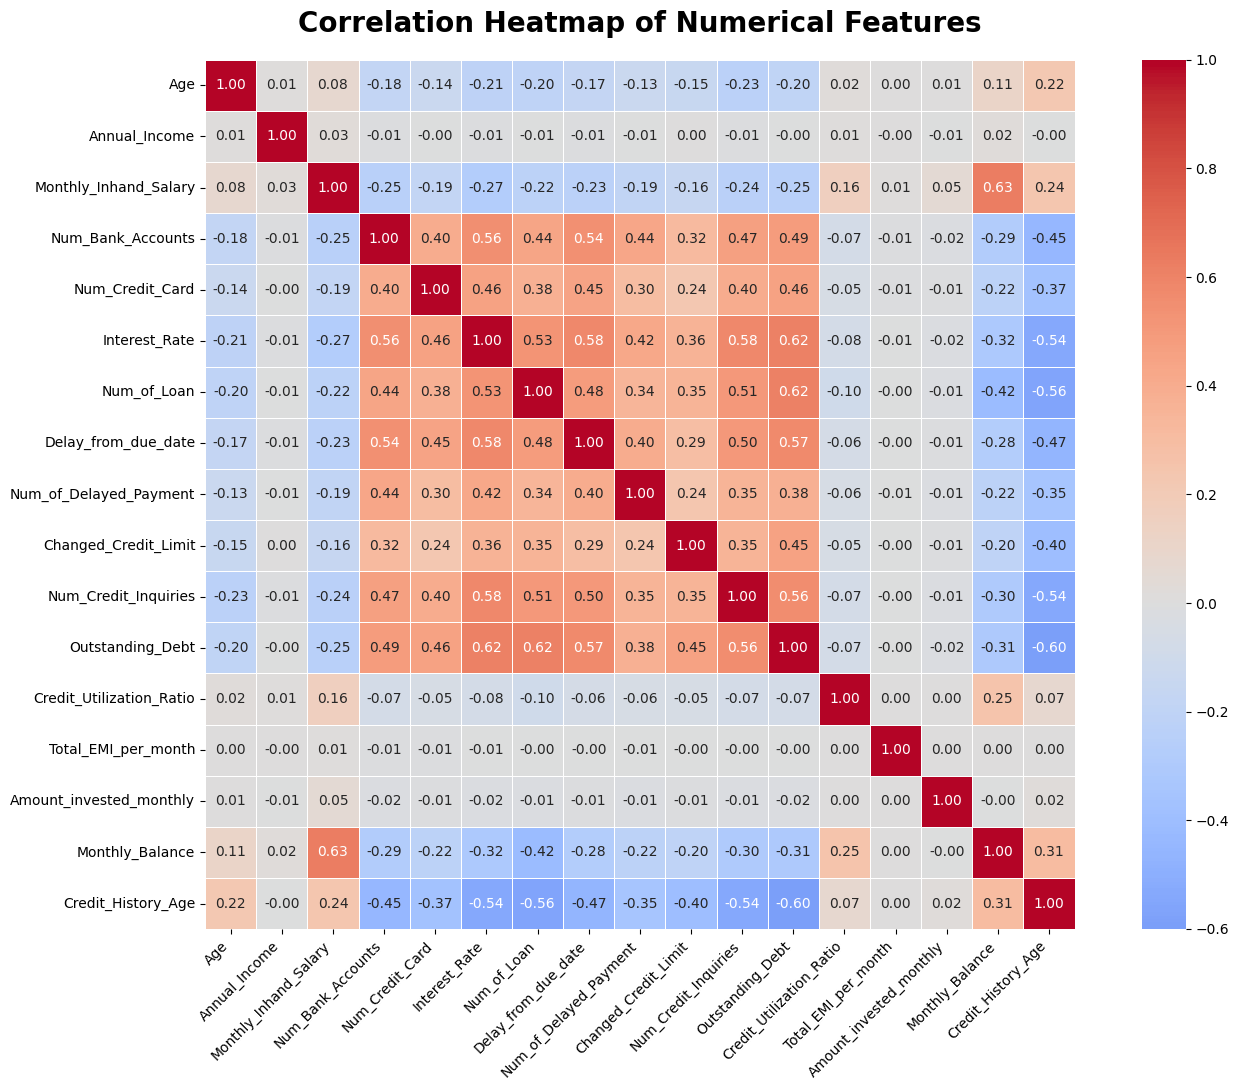

In [52]:
# Calculate correlation
corr = clean_train_data[numeric_cols].corr()

# Create heatmap
plt.figure(figsize=(15, 11))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5,
    square=True,
    center=0
)

plt.title(
    "Correlation Heatmap of Numerical Features",
    fontsize=20,
    fontweight="bold",
    pad=20
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

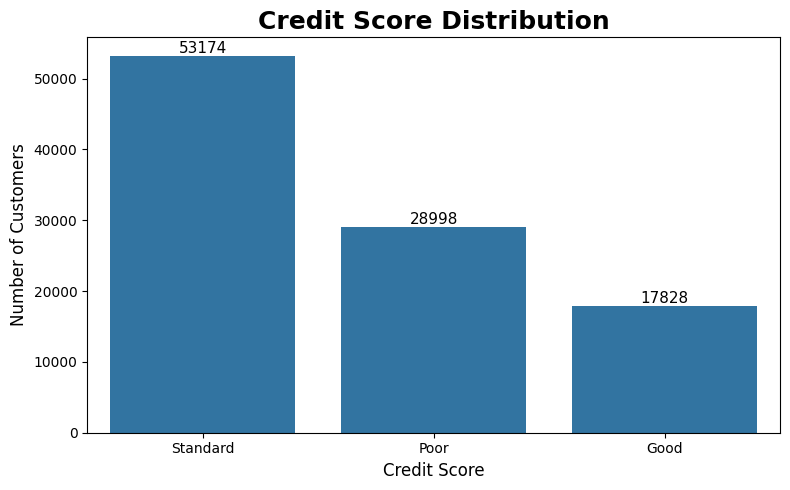

In [53]:
# Credit Score distribution

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=clean_train_data,
    x="Credit_Score",
    order=clean_train_data["Credit_Score"].value_counts().index
)

plt.title("Credit Score Distribution", fontsize=18, fontweight="bold")
plt.xlabel("Credit Score", fontsize=12)
plt.ylabel("Number of Customers", fontsize=12)

# Add values on bars
for container in ax.containers:
    ax.bar_label(container, fontsize=11)

plt.tight_layout()
plt.show()

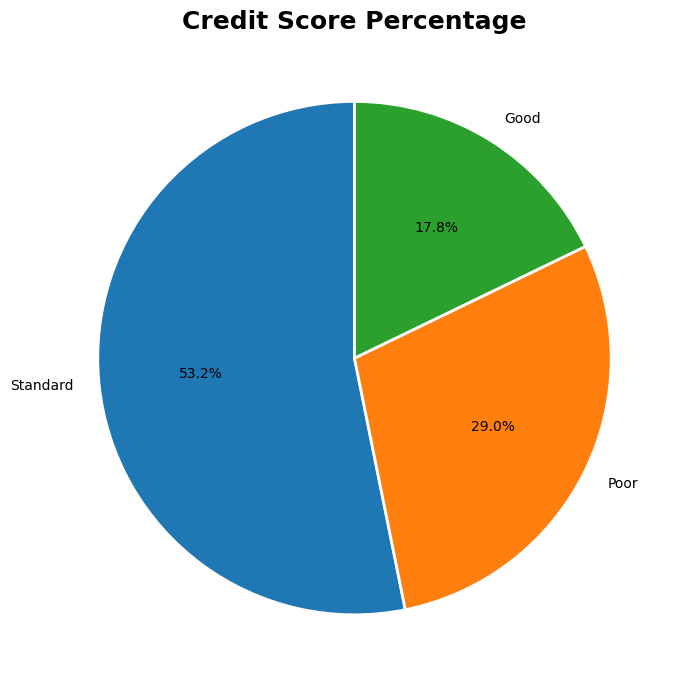

In [54]:
# Calculate percentage
score_percent = (
    clean_train_data["Credit_Score"]
    .value_counts(normalize=True)
    .mul(100)
)

plt.figure(figsize=(7, 7))

plt.pie(
    score_percent,
    labels=score_percent.index,
    autopct="%.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

plt.title(
    "Credit Score Percentage",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

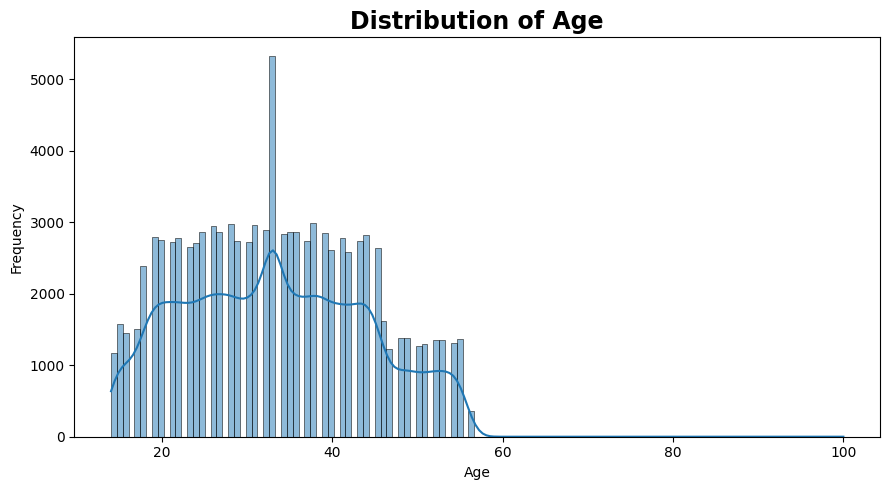

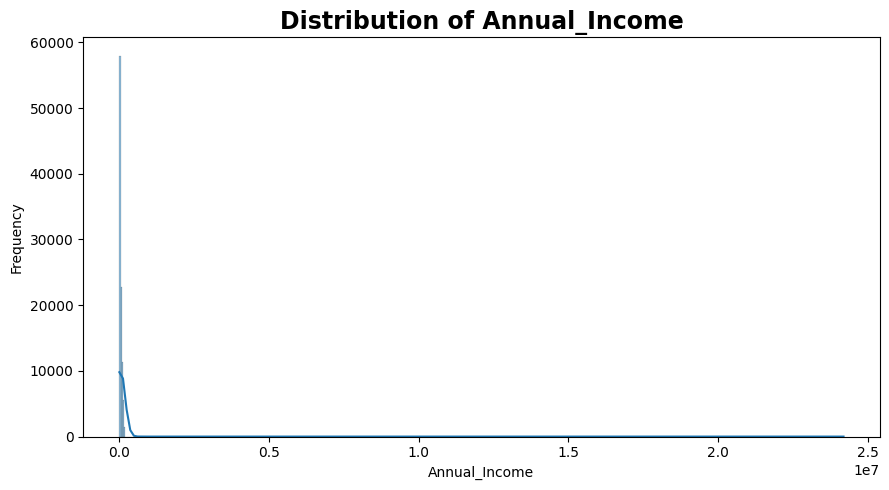

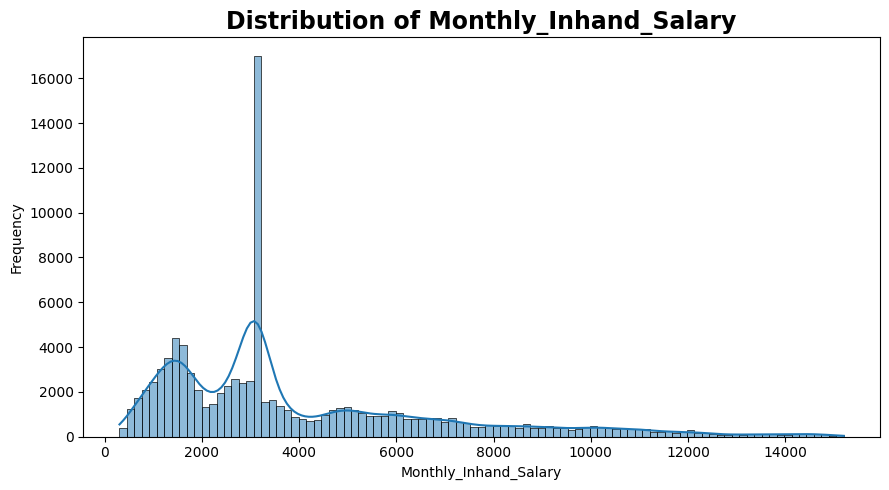

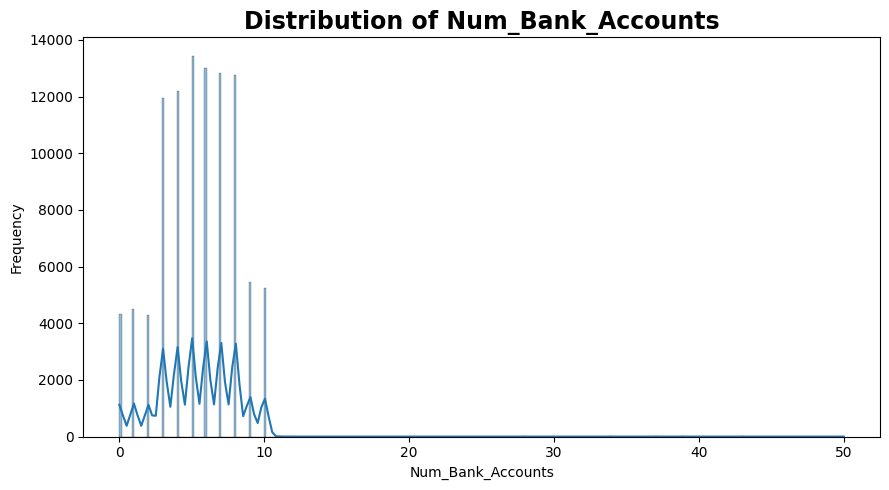

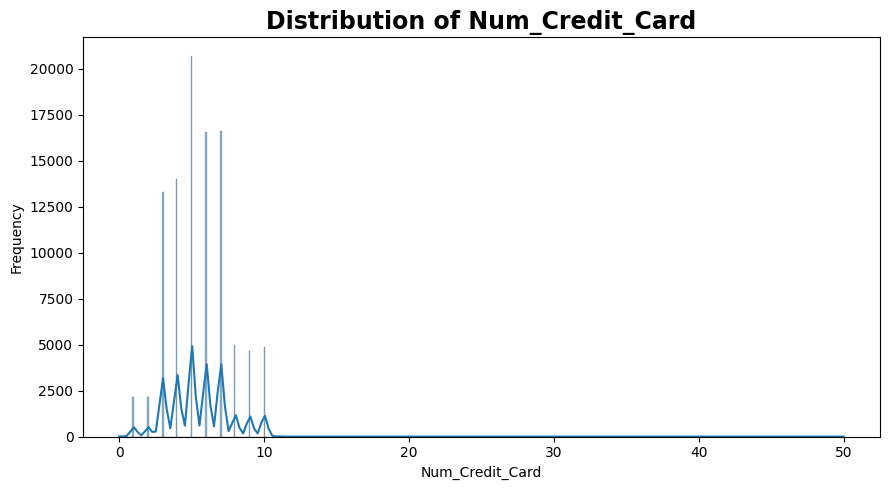

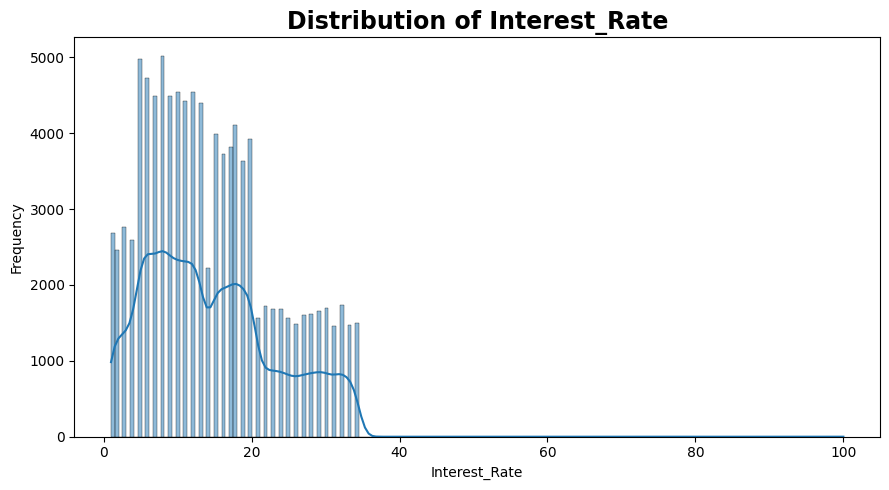

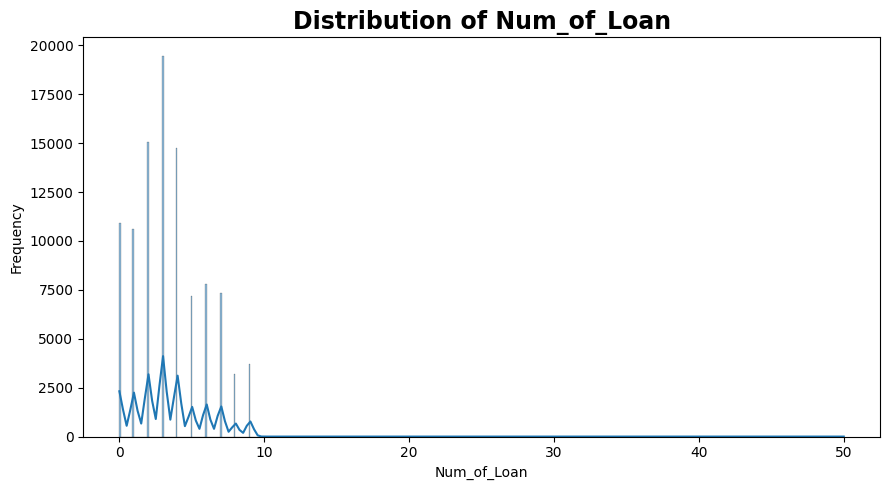

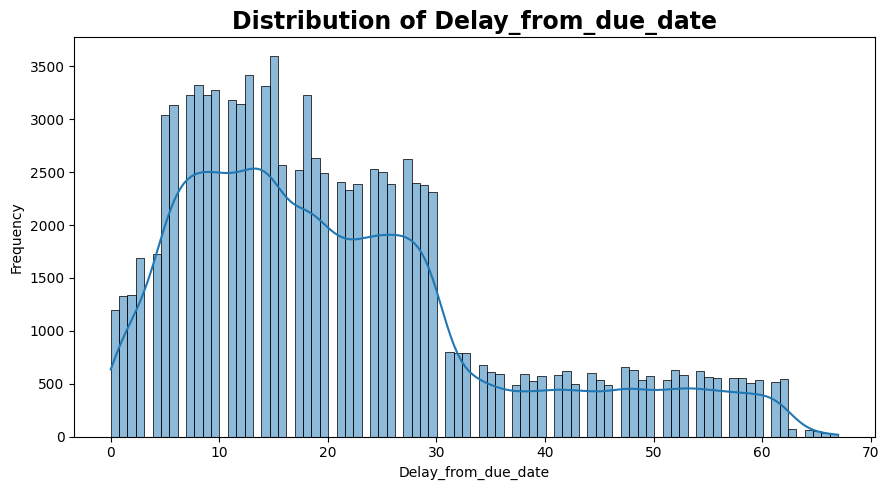

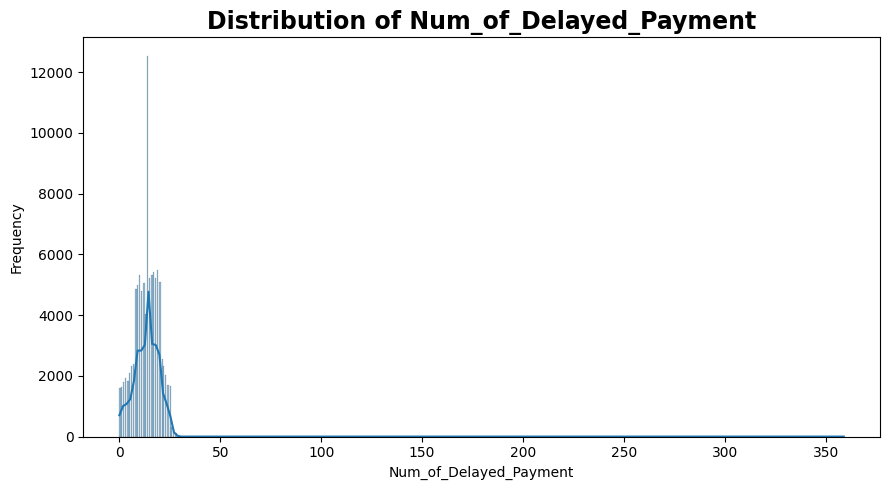

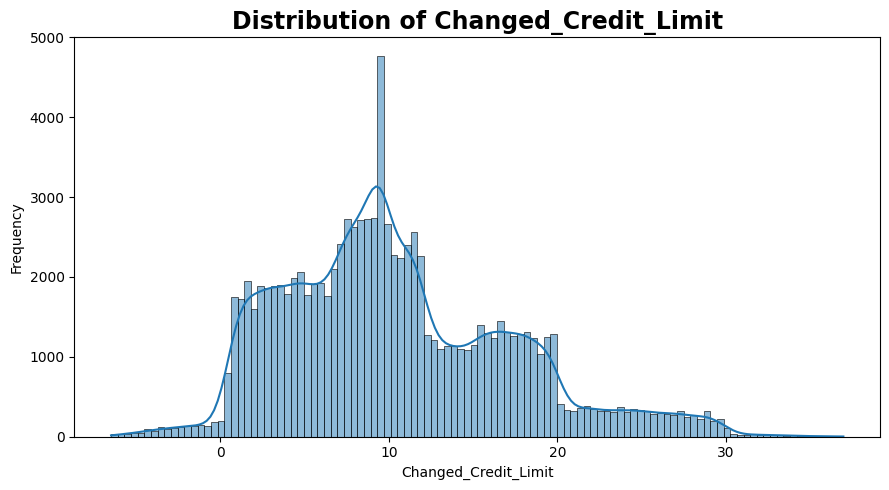

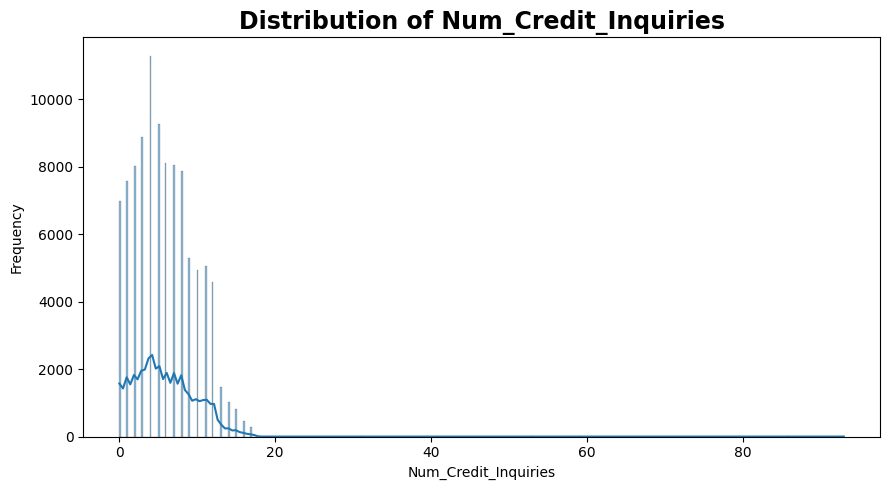

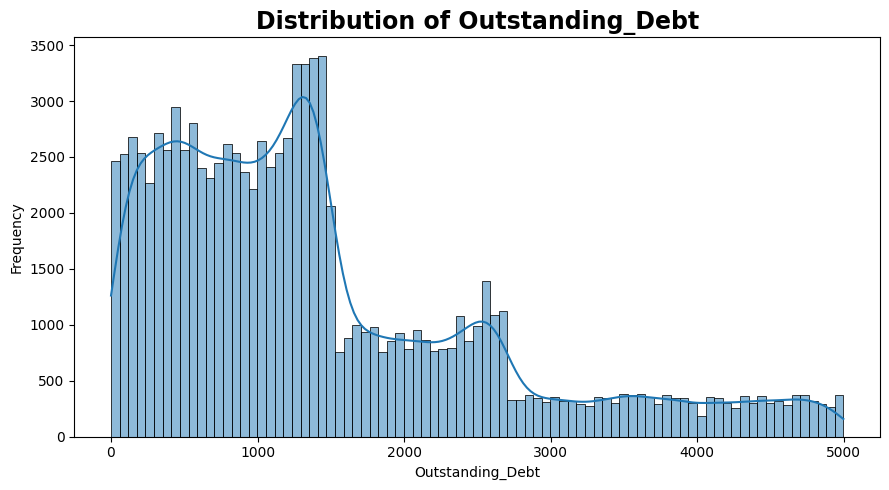

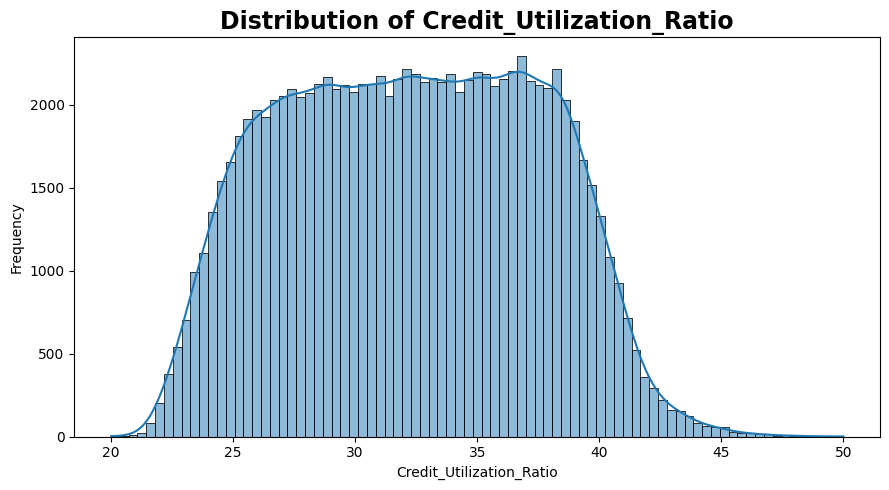

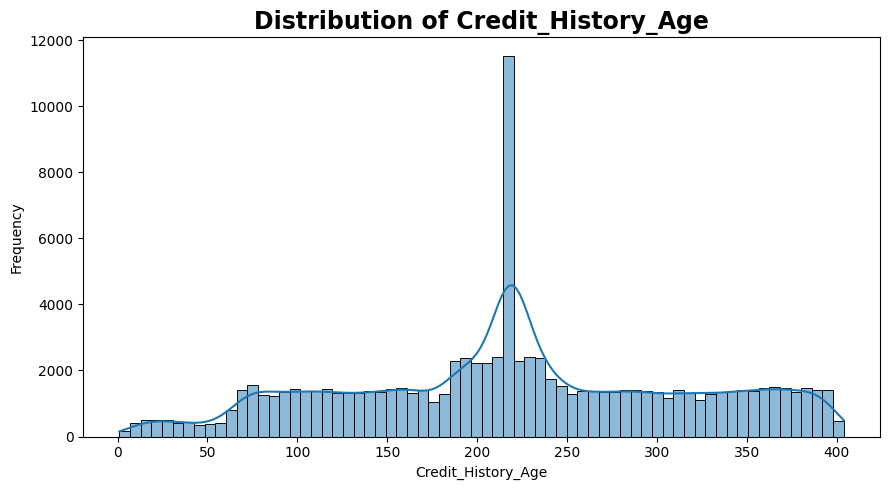

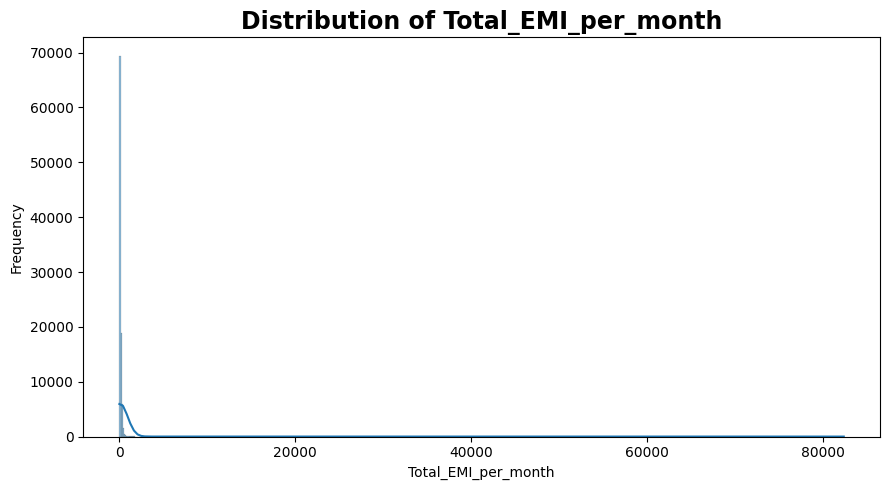

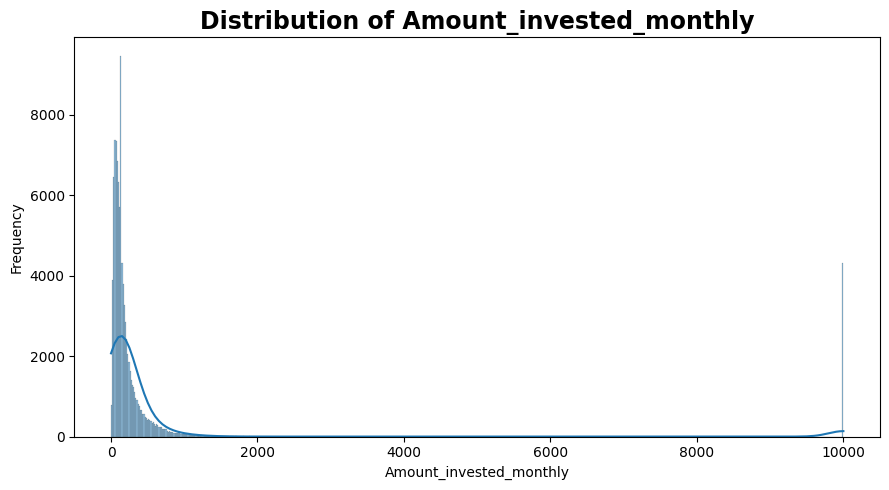

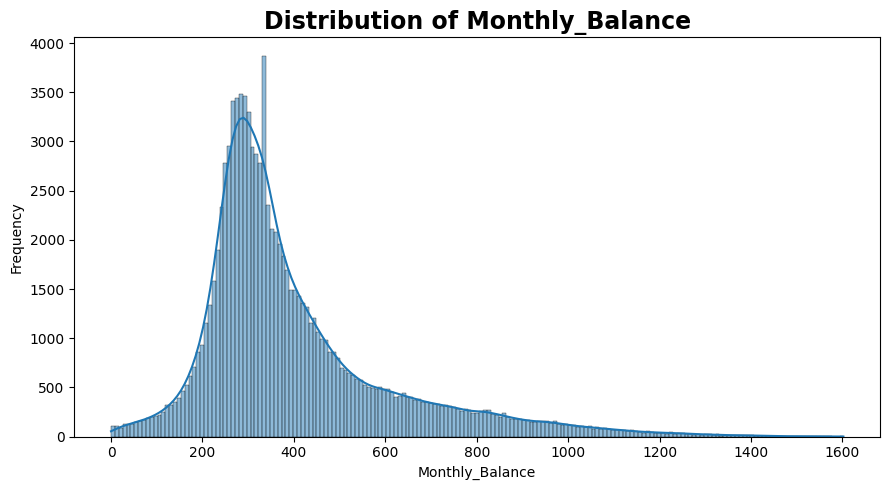

In [55]:
# Get numerical columns
numeric_cols = clean_train_data.select_dtypes(
    include=np.number
).columns.tolist()

# Plot distributions
for col in numeric_cols:

    plt.figure(figsize=(9, 5))

    sns.histplot(
        data=clean_train_data,
        x=col,
        kde=True
    )

    plt.title(
        f"Distribution of {col}",
        fontsize=17,
        fontweight="bold"
    )

    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

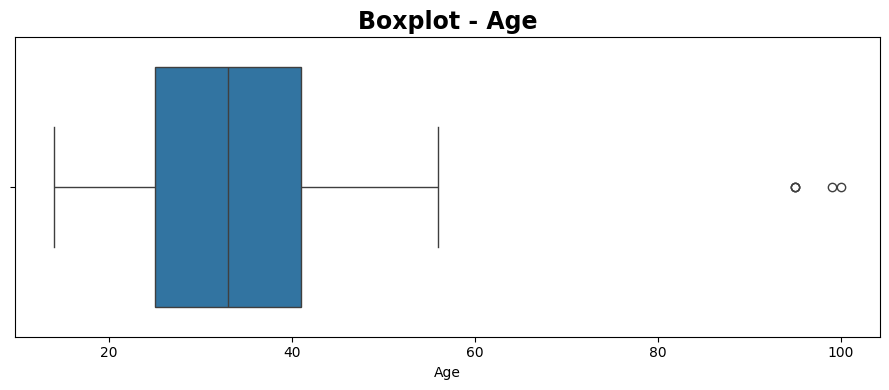

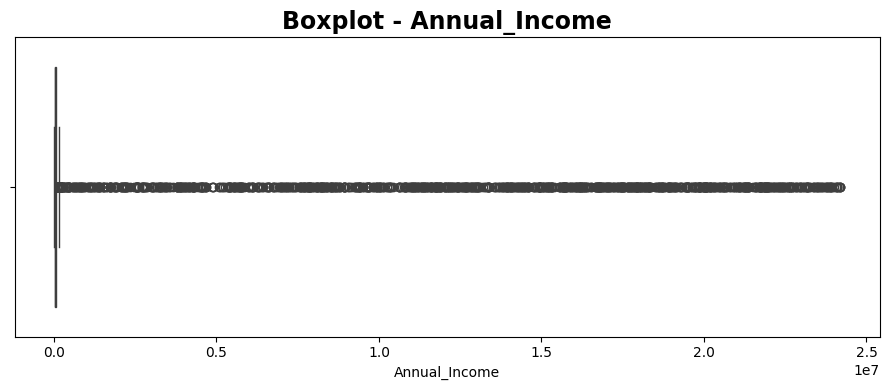

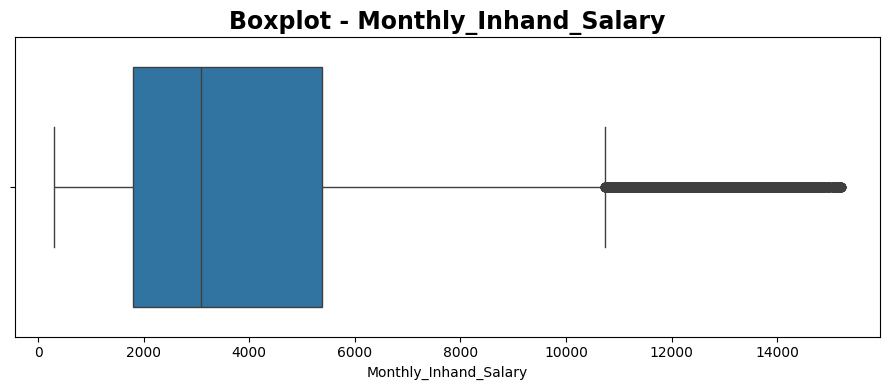

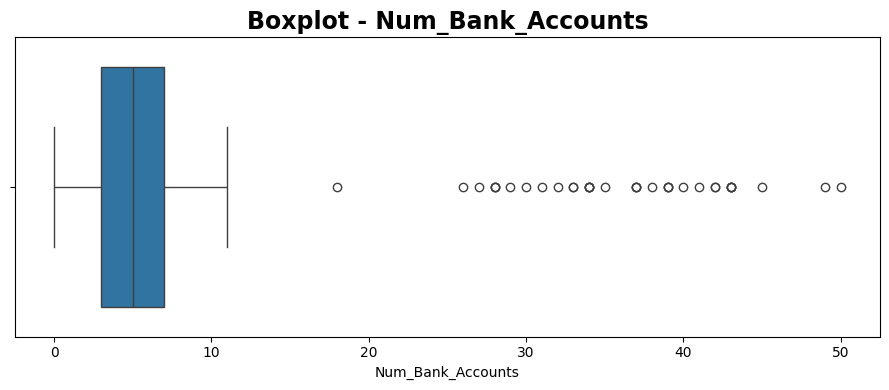

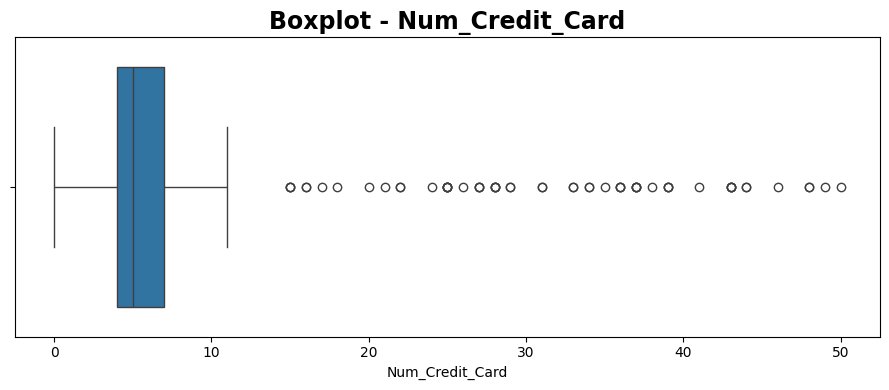

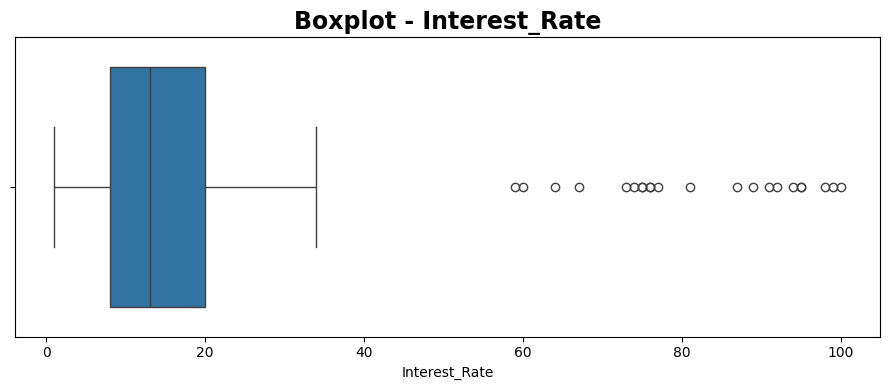

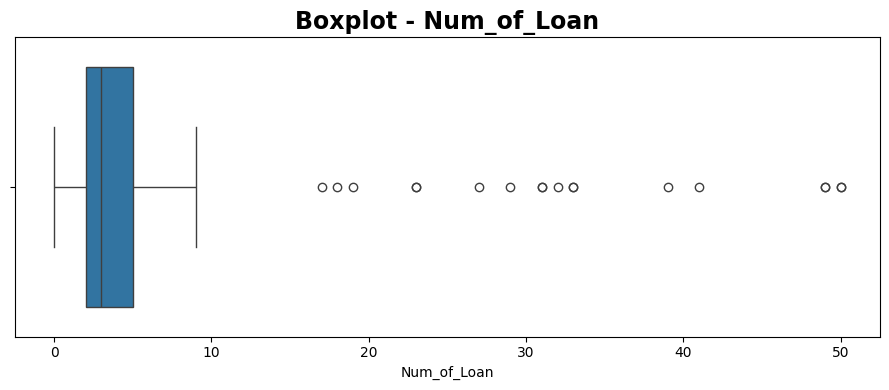

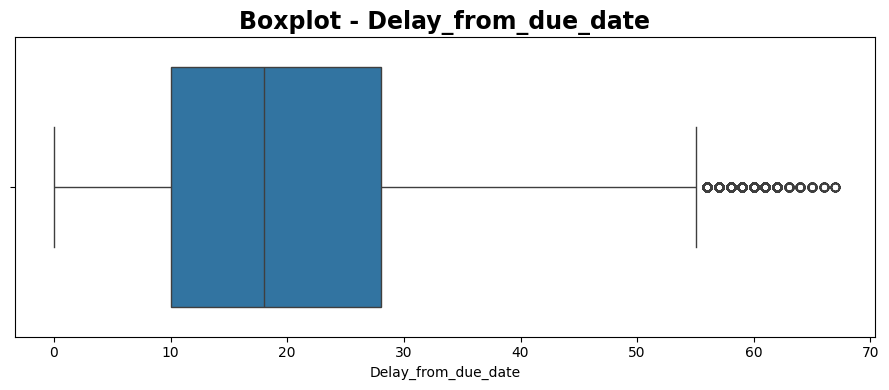

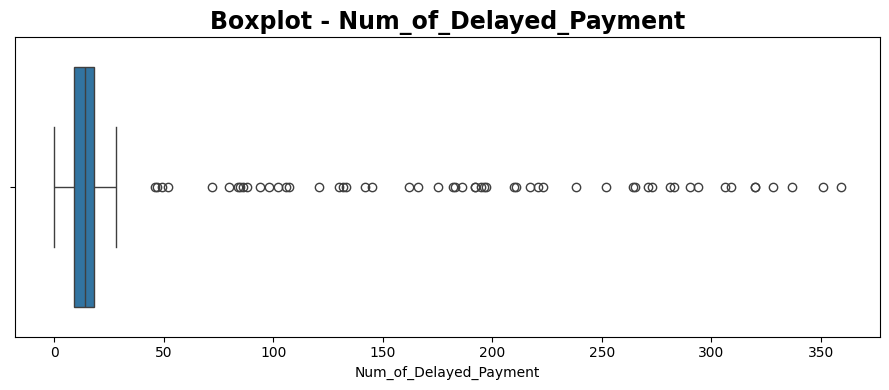

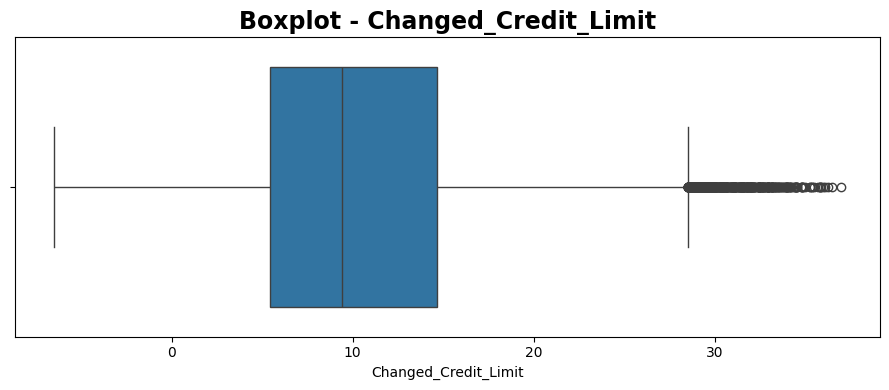

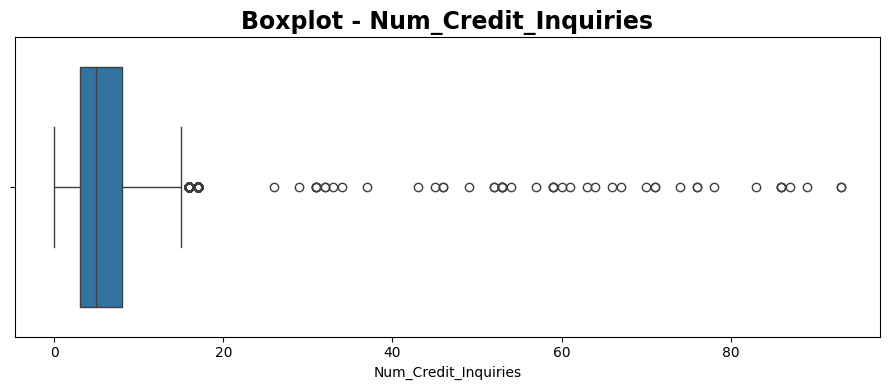

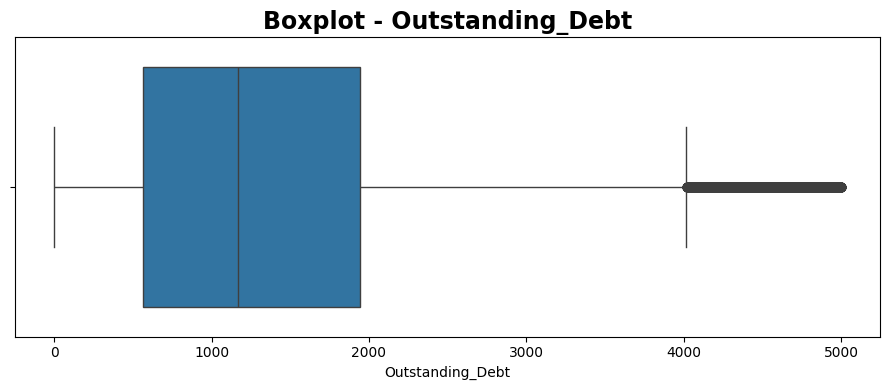

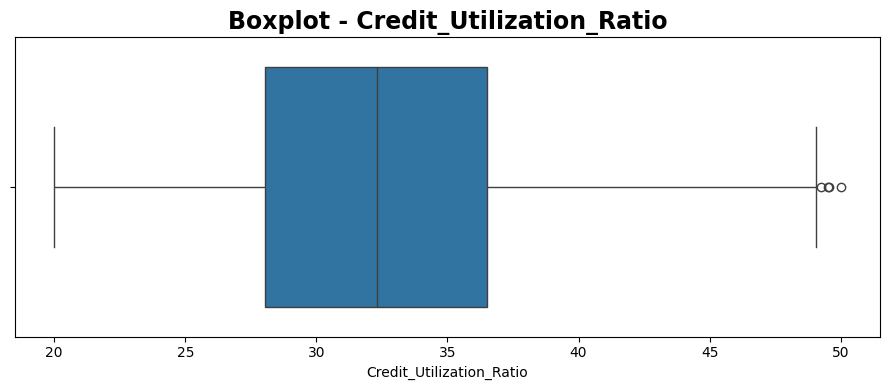

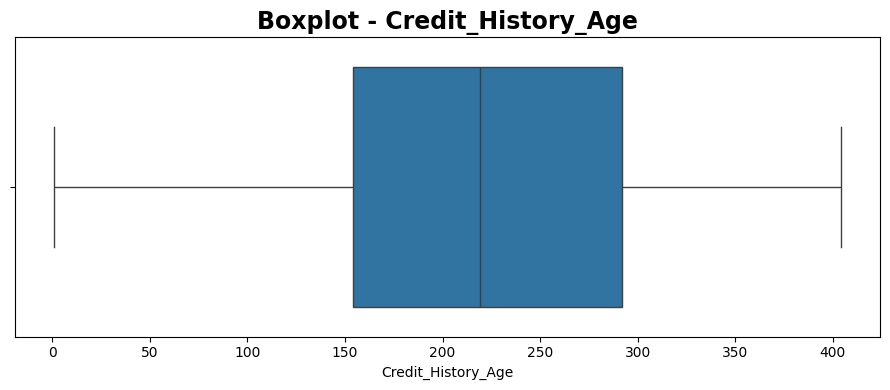

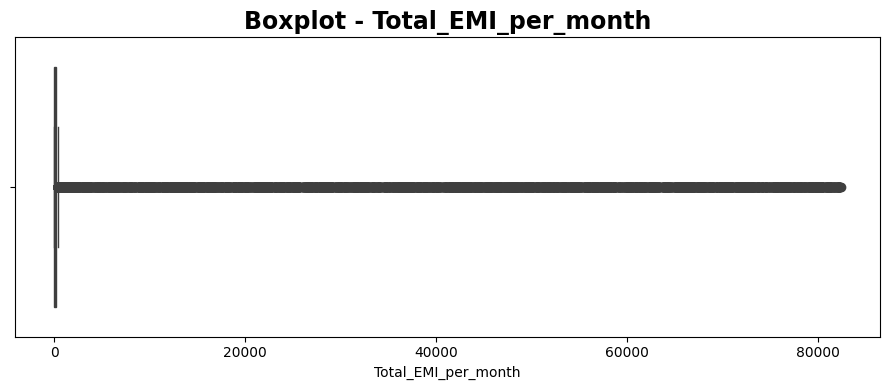

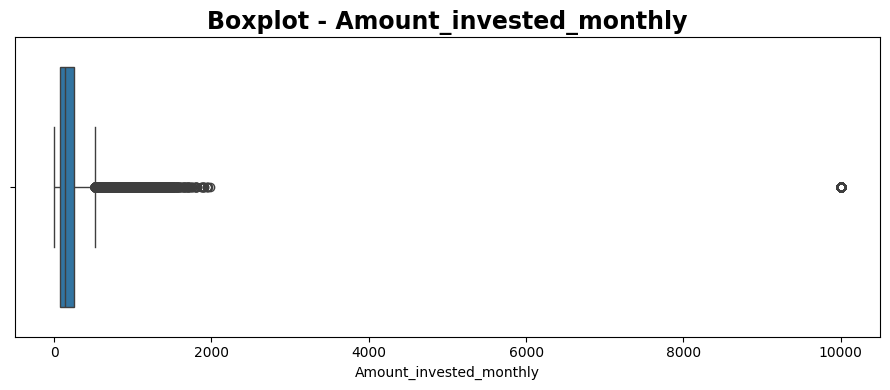

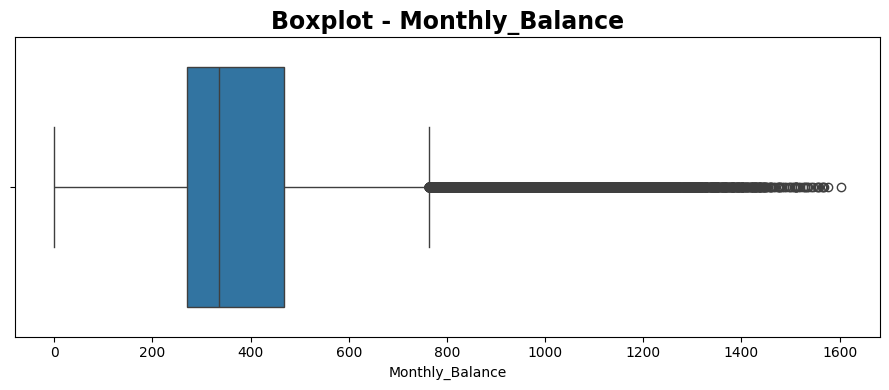

In [56]:
# Plot boxplots
for col in numeric_cols:

    plt.figure(figsize=(9, 4))

    sns.boxplot(
        x=clean_train_data[col]
    )

    plt.title(
        f"Boxplot - {col}",
        fontsize=17,
        fontweight="bold"
    )

    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

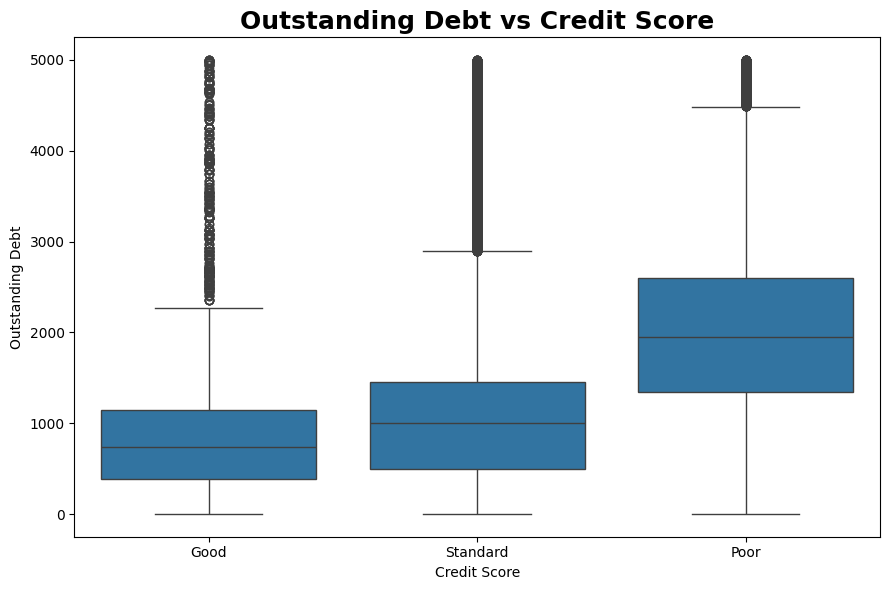

In [57]:
# Outstanding Debt vs Credit Score

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=clean_train_data,
    x="Credit_Score",
    y="Outstanding_Debt"
)

plt.title(
    "Outstanding Debt vs Credit Score",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel("Credit Score")
plt.ylabel("Outstanding Debt")

plt.tight_layout()
plt.show()

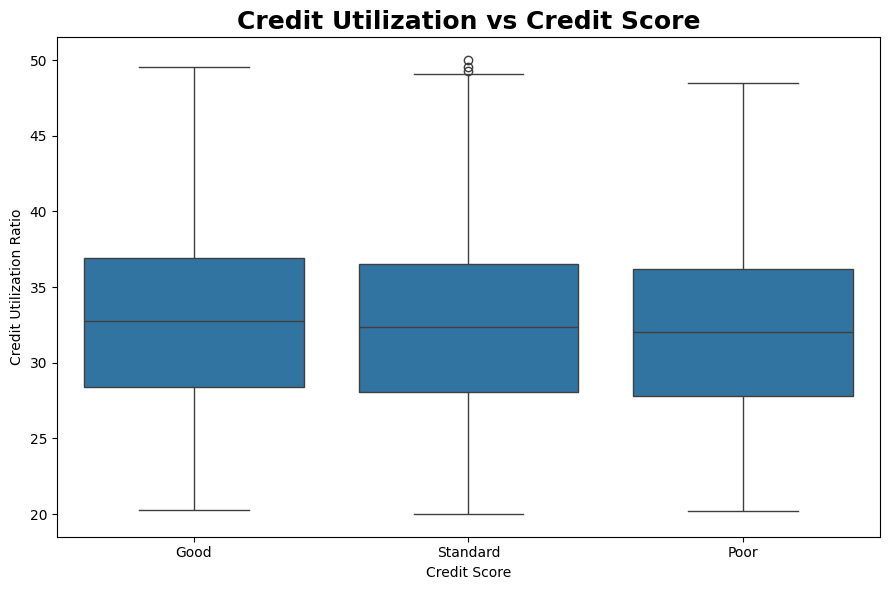

In [58]:
# Credit Utilization vs Credit Score

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=clean_train_data,
    x="Credit_Score",
    y="Credit_Utilization_Ratio"
)

plt.title(
    "Credit Utilization vs Credit Score",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel("Credit Score")
plt.ylabel("Credit Utilization Ratio")

plt.tight_layout()
plt.show()

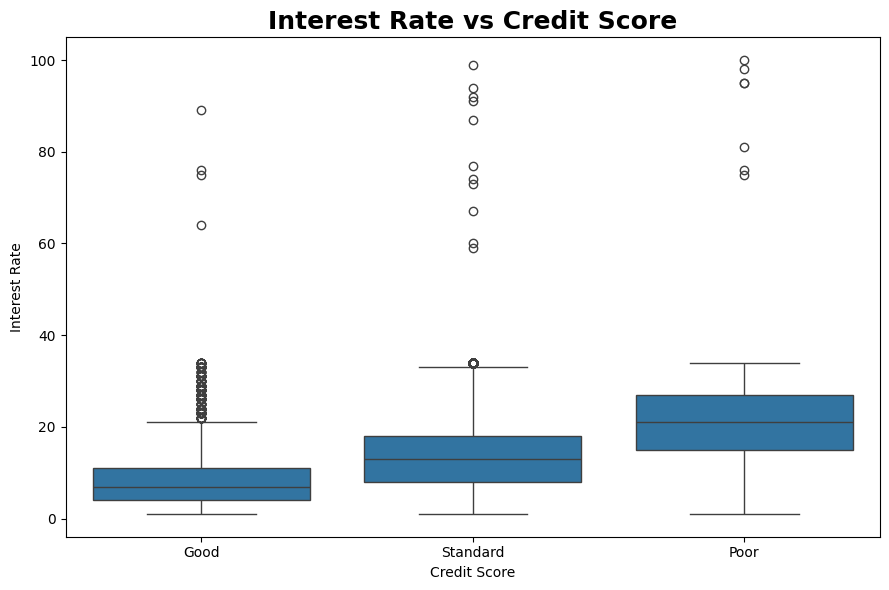

In [59]:
# Interest Rate vs Credit Score

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=clean_train_data,
    x="Credit_Score",
    y="Interest_Rate"
)

plt.title(
    "Interest Rate vs Credit Score",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel("Credit Score")
plt.ylabel("Interest Rate")

plt.tight_layout()
plt.show()

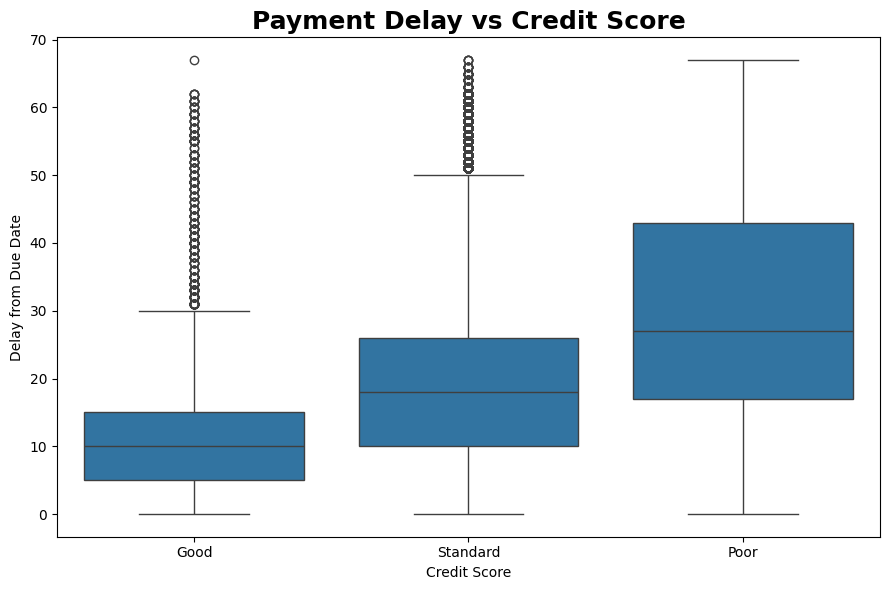

In [60]:
# Payment Delay vs Credit Score

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=clean_train_data,
    x="Credit_Score",
    y="Delay_from_due_date"
)

plt.title(
    "Payment Delay vs Credit Score",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel("Credit Score")
plt.ylabel("Delay from Due Date")

plt.tight_layout()
plt.show()

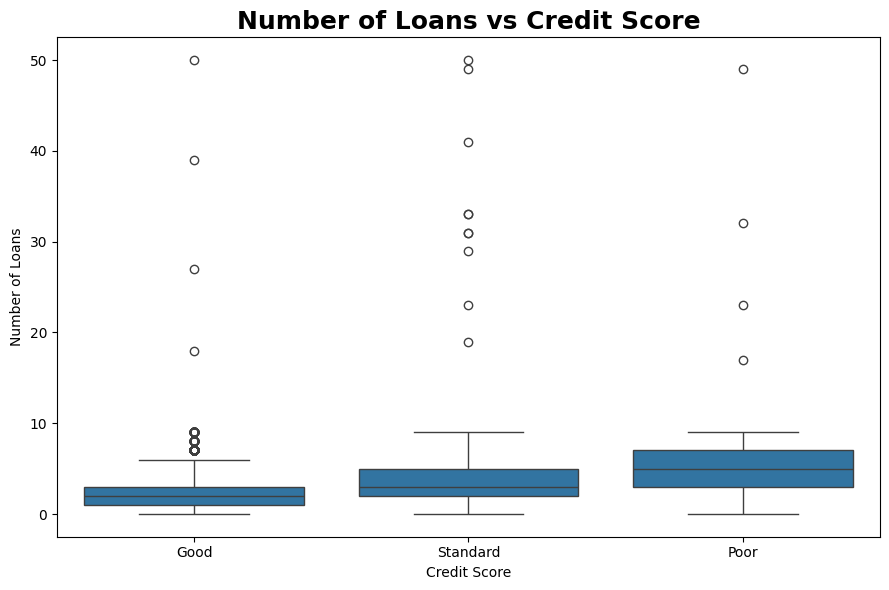

In [61]:
# Number of loans vs Credit Score

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=clean_train_data,
    x="Credit_Score",
    y="Num_of_Loan"
)

plt.title(
    "Number of Loans vs Credit Score",
    fontsize=18,
    fontweight="bold"
)

plt.xlabel("Credit Score")
plt.ylabel("Number of Loans")

plt.tight_layout()
plt.show()

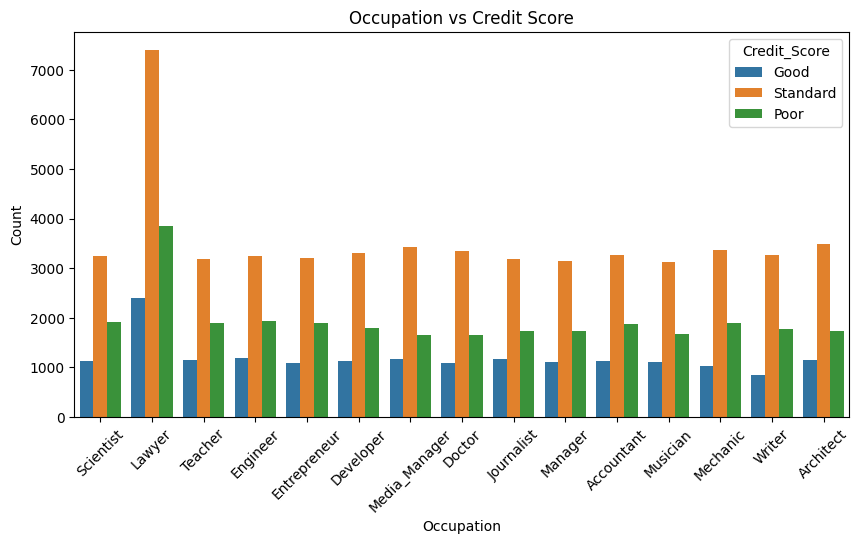

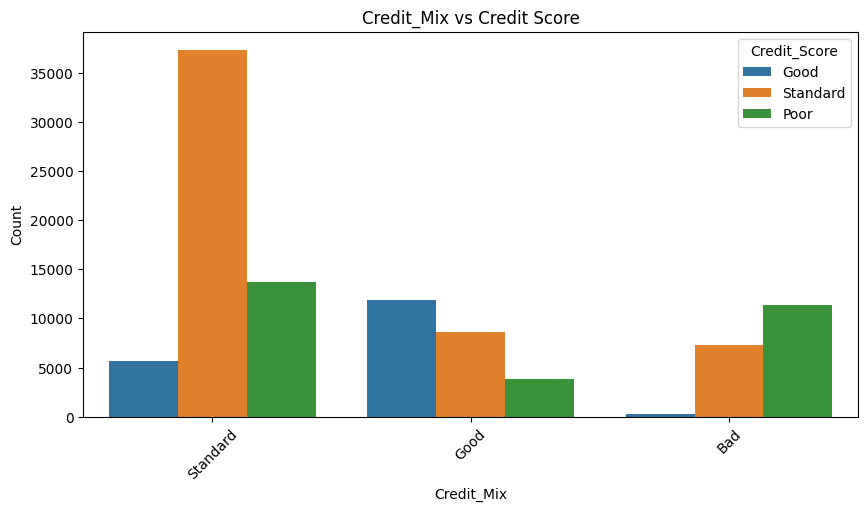

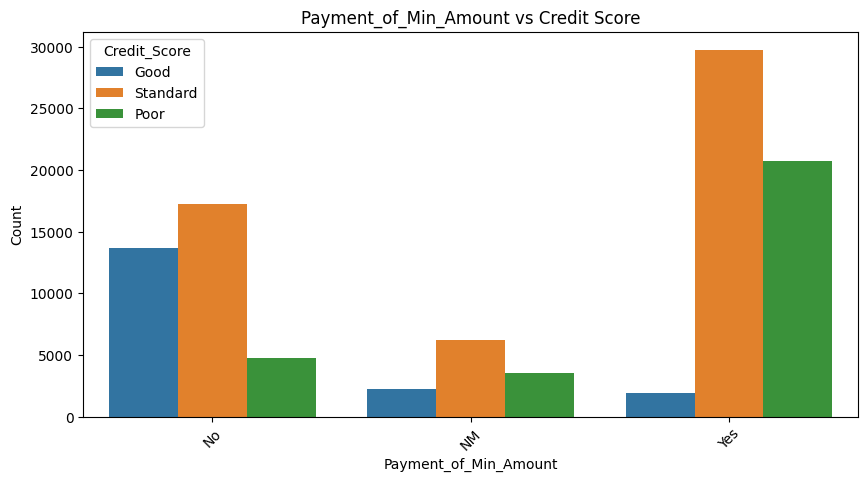

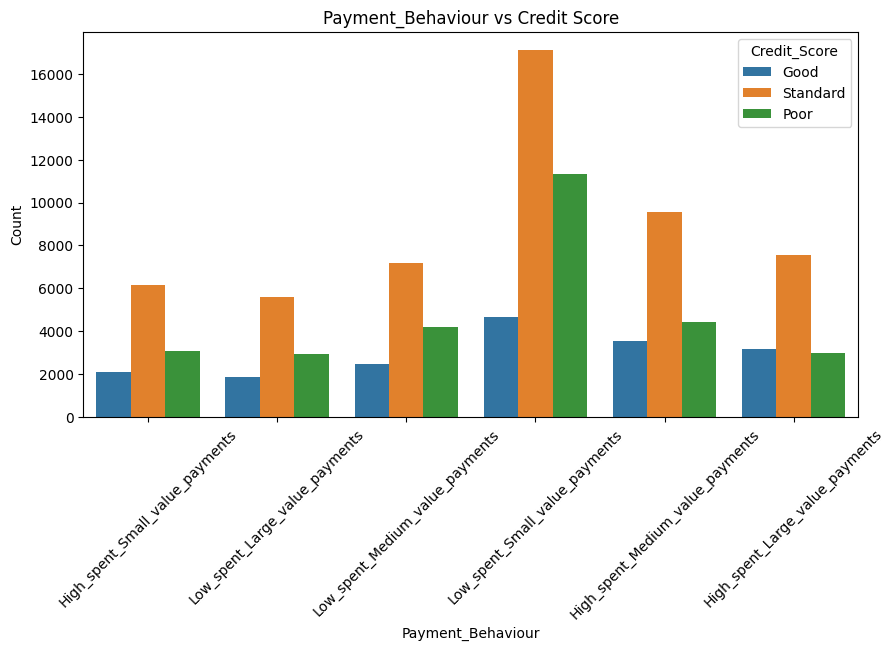

In [62]:
categorical_cols = [
    'Occupation',
    'Credit_Mix',
    'Payment_of_Min_Amount',
    'Payment_Behaviour'
]

for col in categorical_cols:

    plt.figure(figsize=(10, 5))

    sns.countplot(
        data=train_data,
        x=col,
        hue='Credit_Score'
    )

    plt.title(f'{col} vs Credit Score')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45)

    plt.show()

# Encoding

In [63]:
# Find categorical columns
categorical_cols = clean_train_data.select_dtypes(
    include="object"
).columns.tolist()

# Remove target column
categorical_cols.remove("Credit_Score")

print(categorical_cols)

['Month', 'Occupation', 'Type_of_Loan', 'Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour']


In [64]:
# Remove "and " from Type_of_Loan
clean_train_data["Type_of_Loan"] = clean_train_data["Type_of_Loan"].str.replace("and ", "", regex=False)
clean_test_data["Type_of_Loan"] = clean_test_data["Type_of_Loan"].str.replace("and ", "", regex=False)

In [65]:


# Convert loan values into lists
train_loans = clean_train_data["Type_of_Loan"].apply(lambda x: x.split(", "))
test_loans = clean_test_data["Type_of_Loan"].apply(lambda x: x.split(", "))



# Create encoder
mlb = MultiLabelBinarizer()

# Encode train
train_encoded = mlb.fit_transform(train_loans)

# Encode test using train encoder
test_encoded = mlb.transform(test_loans)

# Add encoded columns
train_encoded = pd.DataFrame(
    train_encoded,
    columns=mlb.classes_,
    index=clean_train_data.index
)

test_encoded = pd.DataFrame(
    test_encoded,
    columns=mlb.classes_,
    index=clean_test_data.index
)

# Remove original column
clean_train_data.drop("Type_of_Loan", axis=1, inplace=True)
clean_test_data.drop("Type_of_Loan", axis=1, inplace=True)

# Add encoded columns
clean_train_data = pd.concat([clean_train_data, train_encoded], axis=1)
clean_test_data = pd.concat([clean_test_data, test_encoded], axis=1)

In [66]:
# Create encoder one hot encoder
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

In [67]:
# remove type of loan
categorical_cols.remove("Type_of_Loan")

In [68]:
# Fit encoder on train and transform train
train_encoded = encoder.fit_transform(
    clean_train_data[categorical_cols]
)

In [69]:
# Use the same encoder to transform test
test_encoded = encoder.transform(
    clean_test_data[categorical_cols]
)

In [70]:
# Get encoded column names
encoded_cols = encoder.get_feature_names_out(
    categorical_cols
)

In [71]:
# Convert train encoded data to DataFrame
train_encoded = pd.DataFrame(
    train_encoded,
    columns=encoded_cols,
    index=clean_train_data.index
)

# Convert test encoded data to DataFrame
test_encoded = pd.DataFrame(
    test_encoded,
    columns=encoded_cols,
    index=clean_test_data.index
)

In [72]:
# Remove original categorical columns from train
clean_train_data.drop(
    columns=categorical_cols,
    inplace=True
)

# Remove original categorical columns from test
clean_test_data.drop(
    columns=categorical_cols,
    inplace=True
)

In [73]:
# Add encoded columns to train
clean_train_data = pd.concat(
    [clean_train_data, train_encoded],
    axis=1
)

# Add encoded columns to test
clean_test_data = pd.concat(
    [clean_test_data, test_encoded],
    axis=1
)

In [74]:
# Encode Credit Score
score_map = {
    "Poor": 0,
    "Standard": 1,
    "Good": 2
}

clean_train_data["Credit_Score"] = clean_train_data[
    "Credit_Score"
].map(score_map)

In [75]:
# Check train
print("Train shape:", clean_train_data.shape)
print(clean_train_data.head())

# Check test
print("Test shape:", clean_test_data.shape)
print(clean_test_data.head())

# Check remaining text columns
print("Train text columns:",
      clean_train_data.select_dtypes(include="object").columns.tolist())

print("Test text columns:",
      clean_test_data.select_dtypes(include="object").columns.tolist())

Train shape: (100000, 62)
    Age  Annual_Income  Monthly_Inhand_Salary  Num_Bank_Accounts  \
0  23.0       19114.12            1824.843333                3.0   
1  23.0       19114.12            3093.745000                3.0   
2  33.0       19114.12            3093.745000                3.0   
3  23.0       19114.12            3093.745000                3.0   
4  23.0       19114.12            1824.843333                3.0   

   Num_Credit_Card  Interest_Rate  Num_of_Loan  Delay_from_due_date  \
0              4.0            3.0          4.0                  3.0   
1              4.0            3.0          4.0                 18.0   
2              4.0            3.0          4.0                  3.0   
3              4.0            3.0          4.0                  5.0   
4              4.0            3.0          4.0                  6.0   

   Num_of_Delayed_Payment  Changed_Credit_Limit  ...  Credit_Mix_Standard  \
0                     7.0                 11.27  ...         

In [76]:
clean_train_data.head()

,Age,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,...,Credit_Mix_Standard,Payment_of_Min_Amount_NM,Payment_of_Min_Amount_No,Payment_of_Min_Amount_Yes,Payment_Behaviour_High_spent_Large_value_payments,Payment_Behaviour_High_spent_Medium_value_payments,Payment_Behaviour_High_spent_Small_value_payments,Payment_Behaviour_Low_spent_Large_value_payments,Payment_Behaviour_Low_spent_Medium_value_payments,Payment_Behaviour_Low_spent_Small_value_payments
0,23.0,19114.12,1824.843333,3.0,4.0,3.0,4.0,3.0,7.0,11.27,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,23.0,19114.12,3093.745000,3.0,4.0,3.0,4.0,18.0,14.0,11.27,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,33.0,19114.12,3093.745000,3.0,4.0,3.0,4.0,3.0,7.0,9.40,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,23.0,19114.12,3093.745000,3.0,4.0,3.0,4.0,5.0,4.0,6.27,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,23.0,19114.12,1824.843333,3.0,4.0,3.0,4.0,6.0,14.0,11.27,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [77]:
# Save cleaned train data
clean_train_data.to_csv(
    "encoded_train_data.csv",
    index=False
)

# Save cleaned test data
clean_test_data.to_csv(
    "encoded_test_data.csv",
    index=False
)



In [78]:
# Load encoded datasets
train_data = pd.read_csv("encoded_train_data.csv")
test_data = pd.read_csv("encoded_test_data.csv")

print("Train shape:", train_data.shape)
print("Test shape:", test_data.shape)

Train shape: (100000, 62)
Test shape: (50000, 61)


In [79]:
# Check target column
print(train_data["Credit_Score"].value_counts())

Credit_Score
1    53174
0    28998
2    17828
Name: count, dtype: int64


In [80]:
# Check first rows
display(train_data.head())

# Check data types
print(train_data.dtypes)

# Check missing values
print("\nMissing values:")
print(train_data.isnull().sum().sum())

,Age,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,...,Credit_Mix_Standard,Payment_of_Min_Amount_NM,Payment_of_Min_Amount_No,Payment_of_Min_Amount_Yes,Payment_Behaviour_High_spent_Large_value_payments,Payment_Behaviour_High_spent_Medium_value_payments,Payment_Behaviour_High_spent_Small_value_payments,Payment_Behaviour_Low_spent_Large_value_payments,Payment_Behaviour_Low_spent_Medium_value_payments,Payment_Behaviour_Low_spent_Small_value_payments
0,23.0,19114.12,1824.843333,3.0,4.0,3.0,4.0,3.0,7.0,11.27,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,23.0,19114.12,3093.745000,3.0,4.0,3.0,4.0,18.0,14.0,11.27,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,33.0,19114.12,3093.745000,3.0,4.0,3.0,4.0,3.0,7.0,9.40,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,23.0,19114.12,3093.745000,3.0,4.0,3.0,4.0,5.0,4.0,6.27,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,23.0,19114.12,1824.843333,3.0,4.0,3.0,4.0,6.0,14.0,11.27,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


Age                                                   float64
Annual_Income                                         float64
Monthly_Inhand_Salary                                 float64
Num_Bank_Accounts                                     float64
Num_Credit_Card                                       float64
                                                       ...   
Payment_Behaviour_High_spent_Medium_value_payments    float64
Payment_Behaviour_High_spent_Small_value_payments     float64
Payment_Behaviour_Low_spent_Large_value_payments      float64
Payment_Behaviour_Low_spent_Medium_value_payments     float64
Payment_Behaviour_Low_spent_Small_value_payments      float64
Length: 62, dtype: object

Missing values:
0


In [81]:
# Check Credit Score distribution
print(train_data["Credit_Score"].value_counts())

print("\nPercentage:")
print(
    train_data["Credit_Score"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Credit_Score
1    53174
0    28998
2    17828
Name: count, dtype: int64

Percentage:
Credit_Score
1    53.17
0    29.00
2    17.83
Name: proportion, dtype: float64


In [82]:
# Separate input features and target
X = train_data.drop("Credit_Score", axis=1)
y = train_data["Credit_Score"]

# Test data contains only input features
X_test = test_data.copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Test shape:", X_test.shape)

X shape: (100000, 61)
y shape: (100000,)
Test shape: (50000, 61)


In [83]:
# Check whether train and test have the same features
missing_columns = set(X.columns) - set(X_test.columns)
extra_columns = set(X_test.columns) - set(X.columns)

print("Missing columns in test:", missing_columns)
print("Extra columns in test:", extra_columns)

Missing columns in test: set()
Extra columns in test: set()


In [84]:
# Make test columns follow the same order as train
X_test = X_test[X.columns]

print("Train features:", X.shape[1])
print("Test features :", X_test.shape[1])

Train features: 61
Test features : 61


In [85]:
# Split data while keeping class proportions
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)

Training data: (80000, 61)
Validation data: (20000, 61)


In [86]:
# Check training class distribution
print("Training distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

# Check validation distribution
print("\nValidation distribution:")
print(y_val.value_counts(normalize=True).mul(100).round(2))

Training distribution:
Credit_Score
1    53.17
0    29.00
2    17.83
Name: proportion, dtype: float64

Validation distribution:
Credit_Score
1    53.18
0    28.99
2    17.83
Name: proportion, dtype: float64


In [87]:
# Logistic Regression with scaling
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Train model
lr_model.fit(X_train, y_train)

# Predict
lr_pred = lr_model.predict(X_val)

# Accuracy
print(
    "Logistic Regression Accuracy:",
    accuracy_score(y_val, lr_pred)
)

Logistic Regression Accuracy: 0.64645


In [88]:
# Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Train
rf_model.fit(X_train, y_train)

# Predict
rf_pred = rf_model.predict(X_val)

# Accuracy
print(
    "Random Forest Accuracy:",
    accuracy_score(y_val, rf_pred)
)

Random Forest Accuracy: 0.7893


In [89]:
# XGBoost model
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=3,
    eval_metric="mlogloss",
    random_state=42
)

# Train
xgb_model.fit(X_train, y_train)

# Predict
xgb_pred = xgb_model.predict(X_val)

# Accuracy
print(
    "XGBoost Accuracy:",
    accuracy_score(y_val, xgb_pred)
)

XGBoost Accuracy: 0.76115


In [90]:
# LightGBM model
lgb_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

# Train
lgb_model.fit(X_train, y_train)

# Predict
lgb_pred = lgb_model.predict(X_val)

# Accuracy
print(
    "LightGBM Accuracy:",
    accuracy_score(y_val, lgb_pred)
)

LightGBM Accuracy: 0.74465


In [91]:
# CatBoost model
cat_model = CatBoostClassifier(
    iterations=300,
    depth=6,
    learning_rate=0.05,
    loss_function="MultiClass",
    verbose=False,
    random_state=42
)

# Train
cat_model.fit(X_train, y_train)

# Predict
cat_pred = cat_model.predict(X_val).astype(int).ravel()

# Accuracy
print(
    "CatBoost Accuracy:",
    accuracy_score(y_val, cat_pred)
)

CatBoost Accuracy: 0.7111


In [92]:
# Store all predictions
predictions = {
    "Logistic Regression": lr_pred,
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred,
    "LightGBM": lgb_pred,
    "CatBoost": cat_pred
}

# Compare models
results = []

for name, pred in predictions.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision": precision_score(
            y_val, pred, average="weighted"
        ),
        "Recall": recall_score(
            y_val, pred, average="weighted"
        ),
        "F1": f1_score(
            y_val, pred, average="weighted"
        )
    })

results = pd.DataFrame(results)

# Sort by F1 score
results = results.sort_values(
    "F1",
    ascending=False
).reset_index(drop=True)

display(results)

,Model,Accuracy,Precision,Recall,F1
0,Random Forest,0.78930,0.788863,0.78930,0.789028
1,XGBoost,0.76115,0.761027,0.76115,0.760867
2,LightGBM,0.74465,0.745709,0.74465,0.744634
3,CatBoost,0.71110,0.713205,0.71110,0.711109
4,Logistic Regression,0.64645,0.645217,0.64645,0.642249


In [93]:
best_rf = rf_model

print("Current Random Forest")
print("Accuracy:", accuracy_score(y_val, rf_pred))
print("F1:", f1_score(y_val, rf_pred, average="weighted"))

Current Random Forest
Accuracy: 0.7893
F1: 0.7890276937140008


In [94]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    best_rf,
    X,
    y,
    cv=cv,
    scoring="f1_weighted",
    n_jobs=-1
)

print("CV Scores:", cv_scores)
print("Mean CV F1:", cv_scores.mean())
print("Std:", cv_scores.std())

CV Scores: [0.78954649 0.7877834  0.78869939 0.78713058 0.77920114]
Mean CV F1: 0.7864721990054762
Std: 0.003726465323939355


In [103]:
# Smaller parameter range
rf_params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 15, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"]
}

In [104]:
# Faster tuning
rf_search = RandomizedSearchCV(
    RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    rf_params,
    n_iter=15,
    cv=3,
    scoring="f1_weighted",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Run tuning
rf_search.fit(X_train, y_train)

print("Best Parameters:")
print(rf_search.best_params_)

print("Best CV F1:")
print(rf_search.best_score_)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best Parameters:
{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}
Best CV F1:
0.7593148173317221


In [105]:
# Get best Random Forest
tuned_rf = rf_search.best_estimator_

print(tuned_rf)

RandomForestClassifier(max_depth=20, n_estimators=300, n_jobs=-1,
                       random_state=42)


In [106]:
# Get best Random Forest
tuned_rf = rf_search.best_estimator_

print(tuned_rf)

RandomForestClassifier(max_depth=20, n_estimators=300, n_jobs=-1,
                       random_state=42)


In [107]:
# Predict validation data
tuned_pred = tuned_rf.predict(X_val)

# Show results
print("Accuracy:", accuracy_score(y_val, tuned_pred))
print("Precision:", precision_score(y_val, tuned_pred, average="weighted"))
print("Recall:", recall_score(y_val, tuned_pred, average="weighted"))
print("F1:", f1_score(y_val, tuned_pred, average="weighted"))

Accuracy: 0.774
Precision: 0.7745809868562464
Recall: 0.774
F1: 0.7742169329172615


In [108]:
# Show detailed results
print(
    classification_report(
        y_val,
        tuned_pred,
        target_names=["Poor", "Standard", "Good"]
    )
)

              precision    recall  f1-score   support

        Poor       0.79      0.77      0.78      5799
    Standard       0.80      0.80      0.80     10635
        Good       0.69      0.71      0.70      3566

    accuracy                           0.77     20000
   macro avg       0.76      0.76      0.76     20000
weighted avg       0.77      0.77      0.77     20000



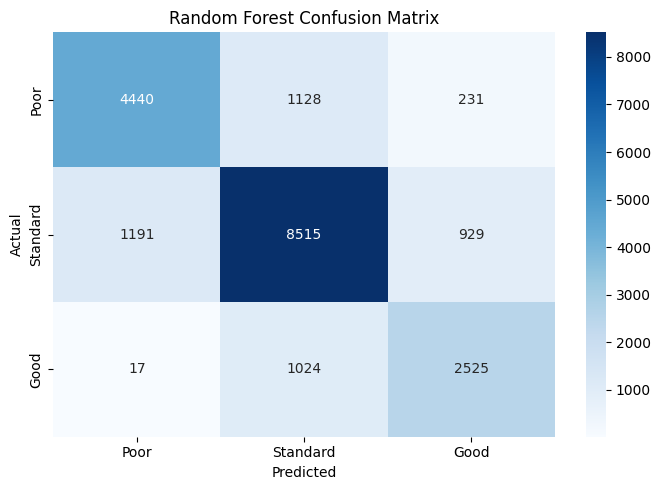

In [109]:
# Create confusion matrix
cm = confusion_matrix(y_val, tuned_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Poor", "Standard", "Good"],
    yticklabels=["Poor", "Standard", "Good"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.tight_layout()
plt.show()

In [110]:
# Calculate old and new scores
old_accuracy = accuracy_score(y_val, rf_pred)
new_accuracy = accuracy_score(y_val, tuned_pred)

old_f1 = f1_score(y_val, rf_pred, average="weighted")
new_f1 = f1_score(y_val, tuned_pred, average="weighted")

print("Original Accuracy:", old_accuracy)
print("Tuned Accuracy:", new_accuracy)

print("Original F1:", old_f1)
print("Tuned F1:", new_f1)

Original Accuracy: 0.7893
Tuned Accuracy: 0.774
Original F1: 0.7890276937140008
Tuned F1: 0.7742169329172615


In [111]:
#now tunig xgboost
xgb_params = {
    "n_estimators": [150, 250, 350, 400],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.8, 0.9, 1.0],
    "colsample_bytree": [0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5],
    "gamma": [0, 0.1, 0.2]
}

In [112]:
xgb_search = RandomizedSearchCV(
    estimator=XGBClassifier(
        objective="multi:softmax",
        num_class=3,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=xgb_params,
    n_iter=10,
    cv=3,
    scoring="f1_weighted",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train, y_train)

print("Best Parameters:")
print(xgb_search.best_params_)

print("\nBest CV F1:")
print(xgb_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters:
{'subsample': 0.8, 'n_estimators': 150, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.1, 'gamma': 0.2, 'colsample_bytree': 0.9}

Best CV F1:
0.7309075029830291


In [113]:
tuned_xgb = xgb_search.best_estimator_

print(tuned_xgb)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.9, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=0.2,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=5, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=150, n_jobs=-1, num_class=3, ...)


In [114]:
tuned_xgb_pred = tuned_xgb.predict(X_val)

print("Accuracy:",
      accuracy_score(y_val, tuned_xgb_pred))

print("Precision:",
      precision_score(
          y_val,
          tuned_xgb_pred,
          average="weighted"
      ))

print("Recall:",
      recall_score(
          y_val,
          tuned_xgb_pred,
          average="weighted"
      ))

print("F1:",
      f1_score(
          y_val,
          tuned_xgb_pred,
          average="weighted"
      ))

Accuracy: 0.73725
Precision: 0.7383110076691197
Recall: 0.73725
F1: 0.7372293711932278


In [115]:
original_xgb_accuracy = accuracy_score(y_val, xgb_pred)
tuned_xgb_accuracy = accuracy_score(y_val, tuned_xgb_pred)

original_xgb_f1 = f1_score(
    y_val,
    xgb_pred,
    average="weighted"
)

tuned_xgb_f1 = f1_score(
    y_val,
    tuned_xgb_pred,
    average="weighted"
)

print("Original XGBoost Accuracy:", original_xgb_accuracy)
print("Tuned XGBoost Accuracy:", tuned_xgb_accuracy)

print("Original XGBoost F1:", original_xgb_f1)
print("Tuned XGBoost F1:", tuned_xgb_f1)

Original XGBoost Accuracy: 0.76115
Tuned XGBoost Accuracy: 0.73725
Original XGBoost F1: 0.7608672925668107
Tuned XGBoost F1: 0.7372293711932278


In [116]:
print(
    classification_report(
        y_val,
        tuned_xgb_pred,
        target_names=["Poor", "Standard", "Good"]
    )
)

              precision    recall  f1-score   support

        Poor       0.76      0.70      0.73      5799
    Standard       0.76      0.78      0.77     10635
        Good       0.64      0.67      0.65      3566

    accuracy                           0.74     20000
   macro avg       0.72      0.72      0.72     20000
weighted avg       0.74      0.74      0.74     20000



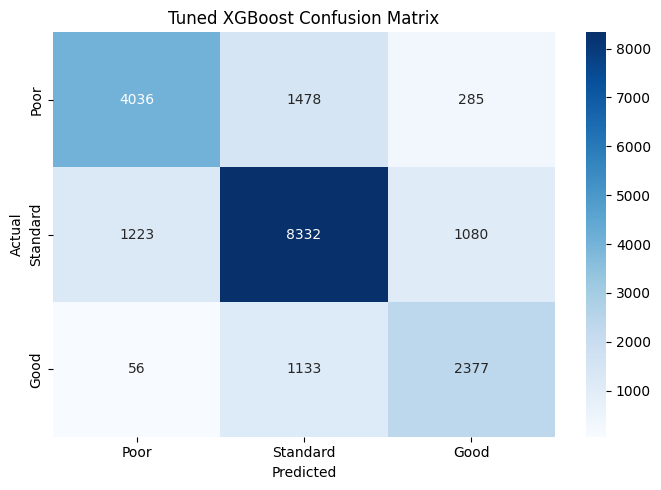

In [117]:
cm = confusion_matrix(y_val, tuned_xgb_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Poor", "Standard", "Good"],
    yticklabels=["Poor", "Standard", "Good"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Tuned XGBoost Confusion Matrix")

plt.tight_layout()
plt.show()

In [118]:
comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Original XGBoost",
        "Tuned XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_val, rf_pred),
        original_xgb_accuracy,
        tuned_xgb_accuracy
    ],
    "F1": [
        f1_score(y_val, rf_pred, average="weighted"),
        original_xgb_f1,
        tuned_xgb_f1
    ]
})

comparison = comparison.sort_values(
    "F1",
    ascending=False
).reset_index(drop=True)

display(comparison)

,Model,Accuracy,F1
0,Random Forest,0.78930,0.789028
1,Original XGBoost,0.76115,0.760867
2,Tuned XGBoost,0.73725,0.737229


# orginal random forest is best 

In [120]:
# Use Random Forest
final_model = rf_model

# Train on all training data
final_model.fit(X, y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [121]:
# Create empty user input
user_input = {}

# Take input for every feature
for column in X.columns:
    user_input[column] = float(input(f"Enter {column}: "))

# Convert to DataFrame
user_df = pd.DataFrame([user_input])

print(user_df)

    Age  Annual_Income  Monthly_Inhand_Salary  Num_Bank_Accounts  \
0  25.0        25555.0                   58.0                5.0   

   Num_Credit_Card  Interest_Rate  Num_of_Loan  Delay_from_due_date  \
0              3.0           55.0          2.0                554.0   

   Num_of_Delayed_Payment  Changed_Credit_Limit  ...  Credit_Mix_Standard  \
0                    54.0                  35.0  ...                  5.0   

   Payment_of_Min_Amount_NM  Payment_of_Min_Amount_No  \
0                       5.0                       5.0   

   Payment_of_Min_Amount_Yes  \
0                        5.0   

   Payment_Behaviour_High_spent_Large_value_payments  \
0                                                5.0   

   Payment_Behaviour_High_spent_Medium_value_payments  \
0                                                5.0    

   Payment_Behaviour_High_spent_Small_value_payments  \
0                                                5.0   

   Payment_Behaviour_Low_spent_Large_value_p

In [122]:
# Make prediction
prediction = final_model.predict(user_df)[0]

# Convert number to Credit Score
score_map = {
    0: "Poor",
    1: "Standard",
    2: "Good"
}

print("Predicted Credit Score:", score_map[int(prediction)])

Predicted Credit Score: Standard


In [123]:
# Get prediction probability
probability = final_model.predict_proba(user_df)[0]

confidence = probability.max() * 100

print("Confidence:", round(confidence, 2), "%")

Confidence: 48.0 %


In [124]:
# Train final Random Forest
final_model = rf_model
final_model.fit(X, y)

# Save model
joblib.dump(final_model, "credit_score_model.pkl")

# Save feature names
joblib.dump(X.columns.tolist(), "feature_names.pkl")

# Save label mapping
score_map = {
    0: "Poor",
    1: "Standard",
    2: "Good"
}

joblib.dump(score_map, "score_map.pkl")

print("Model saved successfully!")

Model saved successfully!
